In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [ ]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy()

In [2]:
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
print(decomp_Mixture.shape)
print(decomp_Basis.shape)
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

(16, 3591898)
(733, 16)
733 3591898


In [3]:
del decomp_Mixture
del decomp_Basis
del fn

In [4]:
DHS_peak_signal_df = pd.read_csv('/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_CT20220208.tsv', delimiter='\t')
DHS_peak_signal_array = DHS_peak_signal_df[DHS_peak_signal_df.columns[2:]].T.to_numpy()
DHS_peak_signal_array.shape

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


(733, 3591898)

In [5]:
del DHS_peak_signal_df

In [ ]:
DHS_mean_signal_df = pd.read_csv('/home/ctrader/NMF_data/DHS_signal_matrix/mean0_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_CT20220209.tsv', delimiter='\t')
DHS_mean_signal_array = DHS_mean_signal_df[DHS_mean_signal_df.columns[2:]].T.to_numpy()
DHS_mean_signal_array.shape

In [ ]:
del DHS_mean_signal_df

In [6]:
DHS_max_signal_df = pd.read_csv('/home/ctrader/NMF_data/DHS_signal_matrix/max_DHS_signal_hg38.75_20.normalized.GRCh38_no_alts_CT20220209.tsv', delimiter='\t')
DHS_max_signal_array = DHS_max_signal_df[DHS_max_signal_df.columns[2:]].T.to_numpy()
DHS_max_signal_array.shape

(733, 3591898)

In [7]:
del DHS_max_signal_df

In [4]:
#results from fill in 0.01%
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_3_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Basis_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Basis_all_delta_0001_3_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [22]:
nmf_comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
# color = ['grey', 'darkorchid', 'deepskyblue', 'slateblue', 'orange', 'slategrey', 'gold', 'royalblue', 'green', 'saddlebrown', 'chocolate', 'olivedrab', 'seagreen', 'darkolivegreen', 'red', 'darkblue']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
biosample_df = df[['library order', 'Biosample name']]

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
del tsv_file
del df
del biosample_df

In [3]:
biosample_id_order = np.array(df['Altius Biosample ID'])
extra_tsv_file = open('/home/meuleman/work/projects/ENCODE3/WM20180608_733_sample_metadata/ENCODE 733-sample list WM20180608 - ENCODE3 metadata.tsv')
extra_biosample_df = pd.read_csv(extra_tsv_file, delimiter="\t")
extra_biosample_df = extra_biosample_df[~extra_biosample_df['BAM file'].isnull()]
# extra_biosample_df['ind'] = extra_biosample_df.index
extra_biosample_df = extra_biosample_df.set_index(['DS_plus'])
extra_biosample_df = extra_biosample_df.loc[biosample_id_order]
extra_biosample_df['ind'] = np.arange(733)
extra_biosample_df['DS_plus'] = extra_biosample_df.index
extra_biosample_df = extra_biosample_df.set_index(['ind'])

In [8]:
df

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,System,Subsystem,Organ,Biosample type,Biological state,Germ layer,Description,Growth stage,Age,Sex,Ethnicity,Donor ID,Biosample protocol,Experiment protocol,Library kit method,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
0,1,GM06990,NaN,ENCSR000EMQ,ENCLB435ZZZ,ENCBS057ENC,AG5636,LN1203,DS7748,DS7784,Hematopoietic,Lymphoid,Blood,Lines,Immortalized,Mesoderm,Lymphoblastoid,Adult,41Y,F,NaN,NaN,Biosample protocol,Experiment protocol,NaN,Sucrose,NaN,50,NaN,NaN,2009-02-23,142681590,0.6790,83639,82918
1,2,HepG2,NaN,ENCSR000ENP,ENCLB480ZZZ,ENCBS114ENC,AG5635,LN1207,DS7764,DS7768,Hepatic,NaN,Liver,Cancer,Cancer,Endoderm,hepatocellular carcinoma,Child,15Y,M,NaN,NaN,Biosample protocol,Experiment protocol,NaN,Sucrose,NaN,50,NaN,NaN,2009-02-23,138826342,0.5858,89748,89235
2,3,hTH1,NaN,ENCSR000EQC,ENCLB591ZZZ,ENCBS345AAA,AG5634,LN1222,DS7840,NaN,Hematopoietic,T-cell,Blood,Primary,Primary,Mesoderm,T1 helper,Adult,25Y?,F?,NaN,Wilson01,Biosample protocol,Experiment protocol,NaN,Sucrose,6.0,534.9,NaN,NaN,2007-06-06,149158633,0.6470,94360,93665
3,4,Hela,NaN,ENCSR000ENO,ENCLB479ZZZ,ENCBS890POO,AG4219,LN1264,DS8200,NaN,Genitourinary,NaN,Uterus,Cancer,Cancer,Ectoderm,Cervical carcinoma,Adult,31Y,F,NaN,NaN,Biosample protocol,Experiment protocol,NaN,new Sucrose,4.0,50,NaN,NaN,2007-08-24,23372724,0.6444,59098,59024
4,5,CACO2,NaN,ENCSR000EMI,ENCLB422ZZZ,ENCBS391ENC,AG4218,LN1269,DS8235,DS8416,Digestive,NaN,Colon,Cancer,Cancer,Endoderm,Colorectal adenocarcinoma,Adult,72Y,M,NaN,NaN,Biosample protocol,Experiment protocol,NaN,Sucrose,8.0,1,NaN,NaN,2007-09-05,22760059,0.7190,29894,29724
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
728,729,fUmbilical_cord,NaN,ENCSR512CWR,ENCLB771UER,ENCBS518LEK,AG7441,LN45036A,DS24820A,NaN,Fetal Life Support,NaN,Umbilical Cord,Primary,Primary,Endoderm,Umbilical_cord,Fetal,59D,U,NaN,H25615,Biosample protocol,Experiment protocol,Thruplex DNA-Seq Q,NaN,NaN,0.9,1260000.0,A+Sucrose,2017-02-17,195057523,0.5652,113517,112469
729,730,fBone_femur,Musculoskeletal,ENCSR805XIF,ENCLB236BWV,ENCBS337FPV,AG7442,LN45038B,DS36206B,NaN,Musculoskeletal,NaN,Bone,Primary,Primary,Mesoderm,h.f.Bone.femur,Fetal,98D,F,NaN,H26513,Biosample protocol,Experiment protocol,Thruplex DNA-Seq Q,NaN,NaN,8.8,1050000.0,A+Sucrose,2017-02-17,252066174,0.5823,146918,145356
730,731,fLiver,NaN,ENCSR562FNN,ENCLB638FEH,ENCBS275VNY,AG7443,LN45070C,DS37372C,NaN,Hepatic,NaN,Liver,Primary,Primary,Endoderm,h.f.liver,Fetal,113D,F,NaN,H26549,Biosample protocol,Experiment protocol,Thruplex DNA-Seq Q,NaN,NaN,4.48,2140000.0,A+Sucrose,NaN,190541422,0.3703,76639,75369
731,732,fPlacenta,NaN,ENCSR552RKI,ENCLB423VBC,ENCBS565KNL,AG8805,LN45072C,DS37386C,NaN,Fetal Life Support,NaN,Placenta,Primary,Primary,Endoderm,placenta,Fetal,102D,U,NaN,H26550,Biosample protocol,Experiment protocol,Thruplex DNA-Seq Q,NaN,NaN,1.325,1050000.0,A+Sucrose,NaN,203699532,0.3869,107611,106022


In [7]:
pd.set_option('display.max_columns', None)
extra_biosample_df

,Included in 827-sample set?,Included in 665-sample set?,DCC SPOT1 >= 0.3?,DCC SPOT1 >= 0.25,DCC SPOT1 >= 0.2,TO BE INCLUDED,Candidate removal -- insert sizes & dupe rate,Candidate removal -- insert sizes,AG,LN,DS,AG_plus,LN_plus,DCC_experiment,DCC_library,DCC_biosample,repls,taxonomy,display name,class,system,subsystem,organ,germ layer,Description,Growth stage,Biological_state,Sample_group,Age,Sex,Ethnicity,Donor_ID,Alt_donor_ID,Unique cellular condition,Grant,Status,DCC SPOT1,SPOT1,SPOT2,SPOT2_num_spots,SPOT2_num_bases,preseq_max,nuclear_dupes,reads_total,reads_adaptercontamination,reads_lowquality,reads_nonnuclear,duplication rate,insert_spike,insert_ratio,lib_submission_date,lib_kit_method,lib_cleanup,lib_dhs_units,lib_frag_analyzer_conc,lib_nuclei_acid_ng,sample_creation_date,sample_dhs_time_minutes,sample_dhs_mg_per_mil_nuclei,sample_dhs_volume_ml,sample_dhs_percent_igepal,sample_dhs_percent_loss,sample_dhs_nuclei_count,sample_dhs_dnasei_units,sample_dhs_protease_inhibitor,tissueculture_creation_date,fractionation_id,fractionation_method,fractionation_yield,fractionation_num_nuclei,BAM file,DS_plus
ind,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,Yes,Yes,Yes,Yes,Yes,Yes,Yes,No,5636.0,1203.0,7748.0,AG5636,LN1203,ENCSR000EMQ,ENCLB435ZZZ,ENCBS057ENC,DS7784,GM06990,GM06990,Lines,Hematopoietic,Lymphoid,Blood,Mesoderm,Lymphoblastoid,Adult,Immortalized,Lines,41Y,F,NaN,NaN,NaN,0,ENCODE3,unpublished,0.6790,0.6545,0.4433,111013.0,49120551.0,320807053.0,76385327.0,238189351.0,0.0,81698194.0,13809567.0,0.535355,NaN,NaN,2009-02-23,NaN,Sucrose,NaN,NaN,50,2010-08-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,/net/seq/data/aggregations/LN1203/aggregation-...,DS7748
1,Yes,Yes,Yes,Yes,Yes,Yes,No,No,5635.0,1207.0,7764.0,AG5635,LN1207,ENCSR000ENP,ENCLB480ZZZ,ENCBS114ENC,DS7768,h.HepG2,HepG2,Lines,Hepatic,NaN,Liver,Endoderm,hepatocellular carcinoma,Child,Cancer,Cancer,15Y,M,NaN,NaN,NaN,1,ENCODE2,published,0.5858,0.5618,0.4482,115158.0,47318563.0,386655881.0,61507725.0,248320583.0,39.0,81883686.0,27610555.0,0.443055,NaN,NaN,2009-02-23,NaN,Sucrose,NaN,NaN,50,2010-08-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,/net/seq/data/aggregations/LN1207/aggregation-...,DS7764
2,Yes,Yes,Yes,Yes,Yes,Yes,No,No,5634.0,1222.0,7840.0,AG5634,LN1222,ENCSR000EQC,ENCLB591ZZZ,ENCBS345AAA,NaN,hTH1,hTH1,Primary,Hematopoietic,T-cell,Blood,Mesoderm,T1 helper,Adult,Primary,Primary,25Y?,F?,NaN,Wilson01,NaN,1,ENCODE2,published,0.6470,0.6243,0.5285,111660.0,54584608.0,365529941.0,70173889.0,232708777.0,0.0,63279764.0,20270380.0,0.470465,NaN,NaN,2007-06-06,NaN,Sucrose,6.0,NaN,534.9,2010-08-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,/net/seq/data/aggregations/LN1222/aggregation-...,DS7840
3,Yes,Yes,Yes,Yes,Yes,Yes,No,No,4219.0,1264.0,8200.0,AG4219,LN1264,ENCSR000ENO,ENCLB479ZZZ,ENCBS890POO,NaN,Hela,Hela,Lines,Genitourinary,NaN,Uterus,Ectoderm,Cervical carcinoma,Adult,Cancer,Cancer,31Y,F,NaN,NaN,NaN,1,ENCODE2,published,0.6444,0.6217,0.5260,81123.0,26493440.0,268974910.0,6376801.0,44192770.0,19.0,10604424.0,10215622.0,0.272831,NaN,NaN,2007-08-24,NaN,new Sucrose,4.0,NaN,50,2010-08-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,/net/seq/data/aggregations/LN1264/aggregation-...,DS8200
4,Yes,Yes,Yes,Yes,Yes,Yes,No,No,4218.0,1269.0,8235.0,AG4218,LN1269,ENCSR000EMI,ENCLB422ZZZ,ENCBS391ENC,DS8416,CACO2,CACO2,Lines,Digestive,NaN,Colon,Endoderm,Colorectal adenocarcinoma,Adult,Cancer,Cancer,72Y,M,NaN,NaN,NaN,1,ENCODE2,published,0.7190,0.6829,0.5102,36310.0,14966147.0,106079631.0,9441776.0,67349236.0,104.0,43269847.0,1319330.0,0.414842,NaN,NaN,2007-09-05,NaN,Sucrose,8.0,NaN,1,2012-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,/net/seq/data/aggregations/LN1269/aggregation-...,DS8235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,..

In [25]:
DHS_metadata_identifiers = np.array(DHS_metadata['identifier'])

In [26]:
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_identifier_based = DHS_metadata.set_index(['identifier'])
DHS_metadata_identifier_based

,seqname,start,end,mean_signal,numsamples,summit,core_start,core_end,component,ind
identifier,,,,,,,,,,
1.10011,chr1,16140,16200,0.129388,1,16170,16170,16170,Tissue invariant,0
1.10021,chr1,51868,52040,0.0800339,1,51970,51970,51970,Placental / trophoblast,1
1.10025,chr1,57280,57354,0.2732505,4,57350,57350,57350,Neural,2
1.10027,chr1,66370,66482,0.183715575,8,66430,66410,66430,Primitive / embryonic,3
1.1003,chr1,79100,79231,0.113049,2,79150,79150,79150,Placental / trophoblast,4
...,...,...,...,...,...,...,...,...,...,...
Y.994281,chrY,56882540,56882719,0.038079,1,56882610,56882610.0,56882610.0,Lymphoid,3591893
Y.994286,chrY,56882864,56882980,0.115489,1,56882930,56882930.0,56882930.0,Lymphoid,3591894
Y.994292,chrY,56883733,56883960,0.491377,5,56883830,56883742.0,56883870.0,Placental / trophoblast,3591895


In [27]:
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

In [10]:
#The component number for the summary data corresponds to the NMF component
comp0 = pd.read_table('/home/ctrader/lightfm_data/comp1_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp0 mean'])
comp1 = pd.read_table('/home/ctrader/lightfm_data/comp2_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp1 mean'])
comp2 = pd.read_table('/home/ctrader/lightfm_data/comp3_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp2 mean'])
comp3 = pd.read_table('/home/ctrader/lightfm_data/comp4_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp3 mean'])
comp4 = pd.read_table('/home/ctrader/lightfm_data/comp5_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp4 mean'])
comp5 = pd.read_table('/home/ctrader/lightfm_data/comp6_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp5 mean'])
comp6 = pd.read_table('/home/ctrader/lightfm_data/comp7_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp6 mean'])
comp7 = pd.read_table('/home/ctrader/lightfm_data/comp8_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp7 mean'])
comp8 = pd.read_table('/home/ctrader/lightfm_data/comp9_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp8 mean'])
comp9 = pd.read_table('/home/ctrader/lightfm_data/comp10_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp9 mean'])
comp10 = pd.read_table('/home/ctrader/lightfm_data/comp11_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp10 mean'])
comp11 = pd.read_table('/home/ctrader/lightfm_data/comp12_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp11 mean'])
comp12 = pd.read_table('/home/ctrader/lightfm_data/comp13_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp12 mean'])
comp13 = pd.read_table('/home/ctrader/lightfm_data/comp14_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp13 mean'])
comp14 = pd.read_table('/home/ctrader/lightfm_data/comp15_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp14 mean'])
comp15 = pd.read_table('/home/ctrader/lightfm_data/comp16_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp15 mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [11]:
all_comps_average_signal = comp0[['name', 'comp0 mean']].merge(comp1[['name', 'comp1 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp2[['name', 'comp2 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp3[['name', 'comp3 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp4[['name', 'comp4 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp5[['name', 'comp5 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp6[['name', 'comp6 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp7[['name', 'comp7 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp8[['name', 'comp8 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp9[['name', 'comp9 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp10[['name', 'comp10 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp11[['name', 'comp11 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp12[['name', 'comp12 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp13[['name', 'comp13 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp14[['name', 'comp14 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp15[['name', 'comp15 mean']], how='inner', on='name')
all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)
# all_comps_average_signal['average over all comps'] = (all_comps_average_signal['comp0 mean'] + all_comps_average_signal['comp1 mean'] + all_comps_average_signal['comp2 mean'] + all_comps_average_signal['comp3 mean'] + all_comps_average_signal['comp4 mean'] + all_comps_average_signal['comp5 mean'] + all_comps_average_signal['comp6 mean'] + all_comps_average_signal['comp7 mean'] + all_comps_average_signal['comp8 mean'] + all_comps_average_signal['comp9 mean'] + all_comps_average_signal['comp10 mean'] + all_comps_average_signal['comp11 mean'] + all_comps_average_signal['comp12 mean'] + all_comps_average_signal['comp13 mean'] + all_comps_average_signal['comp14 mean'] + all_comps_average_signal['comp15 mean'])/16
all_comps_average_signal['name'] = all_comps_average_signal['name'].astype(str)
all_comps_average_signal = all_comps_average_signal.set_index(['name'])
# old_columns = list(all_comps_average_signal.columns).extend(['max signal'])
# all_comps_average_signal.columns = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
all_comps_average_signal['max signal'] = all_comps_average_signal.idxmax(axis=1)
# all_comps_average_signal.columns = old_columns



all_comps_average_signal = all_comps_average_signal.loc[DHS_metadata_identifiers]
top_10_percent_T_F = np.array([False]*len(all_comps_average_signal))
top_10_percent_T_F[top_10_percent_DHSs_inds] = True
all_comps_average_signal['top 10 percent'] = top_10_percent_T_F
all_comps_average_signal

/tmp/ipykernel_44012/3344514459.py:16: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)


,comp0 mean,comp1 mean,comp2 mean,comp3 mean,comp4 mean,comp5 mean,comp6 mean,comp7 mean,comp8 mean,comp9 mean,comp10 mean,comp11 mean,comp12 mean,comp13 mean,comp14 mean,comp15 mean,average over all comps,max signal,top 10 percent
name,,,,,,,,,,,,,,,,,,,
1.10011,0.053318,0.046712,0.039907,0.034054,0.029935,0.019642,0.050381,0.044771,0.038645,0.052703,0.028230,0.073723,0.043809,0.059390,0.188392,0.038370,0.052624,comp14 mean,False
1.10021,0.012199,0.006616,0.009675,0.005551,0.009631,0.015424,0.037962,0.003689,0.003913,0.006651,0.014848,0.009479,0.012386,0.008923,0.008113,0.004985,0.010628,comp6 mean,False
1.10025,0.013972,0.010649,0.002742,0.005082,0.004388,0.004117,0.010228,0.085321,0.003772,0.005397,0.006319,0.011102,0.003377,0.002977,0.005027,0.015383,0.011866,comp7 mean,False
1.10027,0.002374,0.003701,0.025612,0.018267,0.005331,0.021985,0.032393,0.008670,0.010130,0.010930,0.006678,0.003414,0.000000,0.005247,0.015185,0.002535,0.010778,comp6 mean,False
1.1003,0.017845,0.008636,0.009204,0.007383,0.013745,0.008851,0.032531,0.006222,0.006340,0.007592,0.031536,0.004111,0.014399,0.013492,0.006270,0.012739,0.012556,comp6 mean,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0.016663,0.013051,0.006976,0.008886,0.013321,0.019894,0.044953,0.010084,0.012202,0.006862,0.017083,0.012507,0.017318,0.012432,0.019537,0.017870,0.015602,comp6 mean,False
Y.994286,0.003373,0.007940,0.003355,0.002987,0.008398,0.005565,0.007886,0.005332,0.002115,0.004837,0.001810,0.005148,0.001989,0.004099,0.007139,0.003393,0.004710,comp4 mean,False
Y.994292,0.034594,0.021025,0.013023,0.017206,0.024326,0.086499,0.231924,0.011905,0.017295,0.018428,0.025081,0.018944,0.029714,0.030595,0.021135,0.143163,0.046554,comp6 mean,False


**Individual delta values**

In [4]:
#fill in 0.01% order
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_1_cycle_CT20220201.pickle', 'rb')
diff_flat_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_2_cycles_CT20220201.pickle', 'rb')
diff_flat_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_3_cycles_CT20220201.pickle', 'rb')
diff_flat_all_delta_0001_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_1_cycle_CT20220201.pickle', 'rb')
sorted_diff_flat_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_2_cycles_CT20220201.pickle', 'rb')
sorted_diff_flat_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_3_cycles_CT20220201.pickle', 'rb')
sorted_diff_flat_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [37]:
#finding biosample and DHS indices for top 100 additions with 0.01% approach
first_100_added_calls_inds = sorted_diff_flat_all_delta_0001_1_cycle[-100:]
first_100_added_calls_inds = np.flip(first_100_added_calls_inds)
first_100_added_calls_delta_vals = diff_flat_all_delta_0001_1_cycle[first_100_added_calls_inds]
first_100_added_calls_biosample_inds = first_100_added_calls_inds//n_DHSs
first_100_added_calls_DHS_inds = first_100_added_calls_inds % n_DHSs

#finding biosample and DHS indices for top 100 removals with 0.01% approach
first_100_removed_calls_inds = sorted_diff_flat_all_delta_0001_1_cycle[:100]
first_100_removed_calls_delta_vals = diff_flat_all_delta_0001_1_cycle[first_100_removed_calls_inds]
first_100_removed_calls_biosample_inds = first_100_removed_calls_inds//n_DHSs
first_100_removed_calls_DHS_inds = first_100_removed_calls_inds % n_DHSs

In [5]:
#finding biosample and DHS indices for top 0.01% additions with 0.01% approach for cycle 1
first_01_added_calls_inds = sorted_diff_flat_all_delta_0001_1_cycle[int(np.round(-0.0001*n_DHSs*n_biosamples)):]
first_01_added_calls_inds = np.flip(first_01_added_calls_inds)
first_01_added_calls_delta_vals = diff_flat_all_delta_0001_1_cycle[first_01_added_calls_inds]
first_01_added_calls_biosample_inds = first_01_added_calls_inds//n_DHSs
first_01_added_calls_DHS_inds = first_01_added_calls_inds % n_DHSs

#finding biosample and DHS indices for top 0.01% removals with 0.01% approach for cycle 1
first_01_removed_calls_inds = sorted_diff_flat_all_delta_0001_1_cycle[:int(np.round(0.0001*n_DHSs*n_biosamples))]
first_01_removed_calls_delta_vals = diff_flat_all_delta_0001_1_cycle[first_01_removed_calls_inds]
first_01_removed_calls_biosample_inds = first_01_removed_calls_inds//n_DHSs
first_01_removed_calls_DHS_inds = first_01_removed_calls_inds % n_DHSs

In [13]:
first_01_added_calls_delta_biosample_DHS = np.vstack((first_01_added_calls_delta_vals, first_01_added_calls_biosample_inds, first_01_added_calls_DHS_inds))
first_01_removed_calls_delta_biosample_DHS = np.vstack((first_01_removed_calls_delta_vals, first_01_removed_calls_biosample_inds, first_01_removed_calls_DHS_inds))

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_added_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'wb')
pickle.dump(first_01_added_calls_delta_biosample_DHS, pickle_out)
pickle_out.close()
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_removed_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'wb')
pickle.dump(first_01_removed_calls_delta_biosample_DHS, pickle_out)
pickle_out.close()

In [2]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_added_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_removed_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

first_01_added_calls_delta_vals = first_01_added_calls_delta_biosample_DHS[0, :]
first_01_added_calls_biosample_inds = first_01_added_calls_delta_biosample_DHS[1, :].astype(int)
first_01_added_calls_DHS_inds = first_01_added_calls_delta_biosample_DHS[2, :].astype(int)

first_01_removed_calls_delta_vals = first_01_removed_calls_delta_biosample_DHS[0, :]
first_01_removed_calls_biosample_inds = first_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
first_01_removed_calls_DHS_inds = first_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [6]:
#finding biosample and DHS indices for top 0.01% additions with 0.01% approach for cycle 2
second_01_added_calls_inds = sorted_diff_flat_all_delta_0001_2_cycles[int(np.round(-0.0001*n_DHSs*n_biosamples)):]
second_01_added_calls_inds = np.flip(second_01_added_calls_inds)
second_01_added_calls_delta_vals = diff_flat_all_delta_0001_2_cycles[second_01_added_calls_inds]
second_01_added_calls_biosample_inds = second_01_added_calls_inds//n_DHSs
second_01_added_calls_DHS_inds = second_01_added_calls_inds % n_DHSs

#finding biosample and DHS indices for top 0.01% removals with 0.01% approach for cycle 2
second_01_removed_calls_inds = sorted_diff_flat_all_delta_0001_2_cycles[:int(np.round(0.0001*n_DHSs*n_biosamples))]
second_01_removed_calls_delta_vals = diff_flat_all_delta_0001_2_cycles[second_01_removed_calls_inds]
second_01_removed_calls_biosample_inds = second_01_removed_calls_inds//n_DHSs
second_01_removed_calls_DHS_inds = second_01_removed_calls_inds % n_DHSs

In [14]:
second_01_added_calls_delta_biosample_DHS = np.vstack((second_01_added_calls_delta_vals, second_01_added_calls_biosample_inds, second_01_added_calls_DHS_inds))
second_01_removed_calls_delta_biosample_DHS = np.vstack((second_01_removed_calls_delta_vals, second_01_removed_calls_biosample_inds, second_01_removed_calls_DHS_inds))

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_added_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'wb')
pickle.dump(second_01_added_calls_delta_biosample_DHS, pickle_out)
pickle_out.close()
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_removed_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'wb')
pickle.dump(second_01_removed_calls_delta_biosample_DHS, pickle_out)
pickle_out.close()

In [3]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_added_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'rb')
second_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_removed_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'rb')
second_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

second_01_added_calls_delta_vals = second_01_added_calls_delta_biosample_DHS[0, :]
second_01_added_calls_biosample_inds = second_01_added_calls_delta_biosample_DHS[1, :].astype(int)
second_01_added_calls_DHS_inds = second_01_added_calls_delta_biosample_DHS[2, :].astype(int)

second_01_removed_calls_delta_vals = second_01_removed_calls_delta_biosample_DHS[0, :]
second_01_removed_calls_biosample_inds = second_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
second_01_removed_calls_DHS_inds = second_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [7]:
#finding biosample and DHS indices for top 0.01% additions with 0.01% approach for cycle 3
third_01_added_calls_inds = sorted_diff_flat_all_delta_0001_3_cycles[int(np.round(-0.0001*n_DHSs*n_biosamples)):]
third_01_added_calls_inds = np.flip(third_01_added_calls_inds)
third_01_added_calls_delta_vals = diff_flat_all_delta_0001_3_cycles[third_01_added_calls_inds]
third_01_added_calls_biosample_inds = third_01_added_calls_inds//n_DHSs
third_01_added_calls_DHS_inds = third_01_added_calls_inds % n_DHSs

#finding biosample and DHS indices for top 0.01% removals with 0.01% approach for cycle 3
third_01_removed_calls_inds = sorted_diff_flat_all_delta_0001_3_cycles[:int(np.round(0.0001*n_DHSs*n_biosamples))]
third_01_removed_calls_delta_vals = diff_flat_all_delta_0001_3_cycles[third_01_removed_calls_inds]
third_01_removed_calls_biosample_inds = third_01_removed_calls_inds//n_DHSs
third_01_removed_calls_DHS_inds = third_01_removed_calls_inds % n_DHSs

In [15]:
third_01_added_calls_delta_biosample_DHS = np.vstack((third_01_added_calls_delta_vals, third_01_added_calls_biosample_inds, third_01_added_calls_DHS_inds))
third_01_removed_calls_delta_biosample_DHS = np.vstack((third_01_removed_calls_delta_vals, third_01_removed_calls_biosample_inds, third_01_removed_calls_DHS_inds))

pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_added_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'wb')
pickle.dump(third_01_added_calls_delta_biosample_DHS, pickle_out)
pickle_out.close()
pickle_out = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_removed_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'wb')
pickle.dump(third_01_removed_calls_delta_biosample_DHS, pickle_out)
pickle_out.close()

In [4]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_added_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'rb')
third_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_removed_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'rb')
third_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

third_01_added_calls_delta_vals = third_01_added_calls_delta_biosample_DHS[0, :]
third_01_added_calls_biosample_inds = third_01_added_calls_delta_biosample_DHS[1, :].astype(int)
third_01_added_calls_DHS_inds = third_01_added_calls_delta_biosample_DHS[2, :].astype(int)

third_01_removed_calls_delta_vals = third_01_removed_calls_delta_biosample_DHS[0, :]
third_01_removed_calls_biosample_inds = third_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
third_01_removed_calls_DHS_inds = third_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [8]:
#interactions that were either added or dropped when NMF was calculated after a 1 fill in at a time approach
total_NMF_100_cycles_changes = np.load('/home/ctrader/Hold/NMF/DHS/fill_in_one_at_a_time_saves/one_at_a_time_changed_interactions_total_NMF_100_cycles_CT20220209.npy')
total_NMF_100_cycles_changes_biosamples = total_NMF_100_cycles_changes[:, 0]
total_NMF_100_cycles_changes_DHSs = total_NMF_100_cycles_changes[:, 1]
total_NMF_100_cycles_changes_delta = total_NMF_100_cycles_changes[:, 3]

Text(0.5, 1.0, 'Comparing Order in which First 100 Calls are Added\nDelta Fill-in, Fill Size=0.01% vs. 1 at a Time')

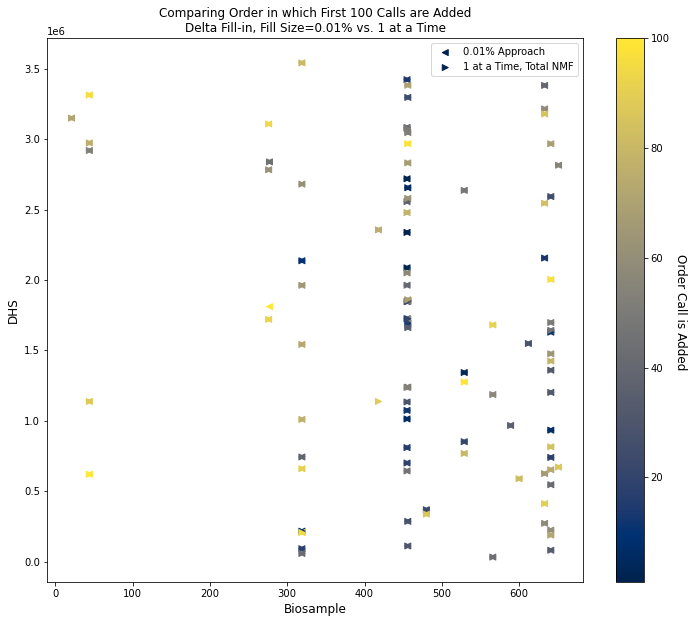

In [11]:
fig = plt.figure(figsize=(12,10))
fig.patch.set_facecolor('white')

scat = plt.scatter(first_01_added_calls_biosample_inds[:100], first_01_added_calls_DHS_inds[:100], marker='<', c=np.arange(100)+1, cmap='cividis')
scat = plt.scatter(total_NMF_100_cycles_changes_biosamples, total_NMF_100_cycles_changes_DHSs, marker='>', c=np.arange(100)+1, cmap='cividis')
fig.colorbar(scat)
fig.text(0.85, 0.5, 'Order Call is Added', va='center', rotation=270, fontsize=12)

# plt.scatter(np.arange(100), first_100_added_calls_biosample_inds, alpha=0.5)
# plt.scatter(np.arange(100), total_NMF_100_cycles_changes_biosamples, alpha=0.5)

# plt.scatter(np.arange(100), biosample_spot_scores[first_100_added_calls_biosample_inds], alpha=0.5)
# plt.scatter(np.arange(100), biosample_spot_scores[total_NMF_100_cycles_changes_biosamples], alpha=0.5)

# plt.scatter(np.arange(100), biosample_DHSs_in_index[first_100_added_calls_biosample_inds], alpha=0.5)
# plt.scatter(np.arange(100), biosample_DHSs_in_index[total_NMF_100_cycles_changes_biosamples], alpha=0.5)

# plt.scatter(np.arange(100), biosample_reads_used[first_100_added_calls_biosample_inds], alpha=0.5)
# plt.scatter(np.arange(100), biosample_reads_used[total_NMF_100_cycles_changes_biosamples], alpha=0.5)

# plt.scatter(np.arange(100), biosample_duplication_rate[first_100_added_calls_biosample_inds], alpha=0.5)
# plt.scatter(np.arange(100), biosample_duplication_rate[total_NMF_100_cycles_changes_biosamples], alpha=0.5)

plt.xlabel('Biosample', fontsize=12)
plt.ylabel('DHS', fontsize=12)
plt.legend(['0.01% Approach', '1 at a Time, Total NMF'])
plt.title('Comparing Order in which First 100 Calls are Added\nDelta Fill-in, Fill Size=0.01% vs. 1 at a Time', fontsize=12)

In [21]:
np.where(np.abs(total_NMF_100_cycles_changes_delta - first_01_added_calls_delta_vals[:100]) >0.001)

(array([19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 34, 35, 36, 37,
        38, 41, 42, 43, 44, 45, 46, 48, 49, 50, 51, 55, 88, 89, 96, 98]),)

Text(0.5, 1.0, 'Comparing Delta Values Between 0.01% and 1 at a Time Methods')

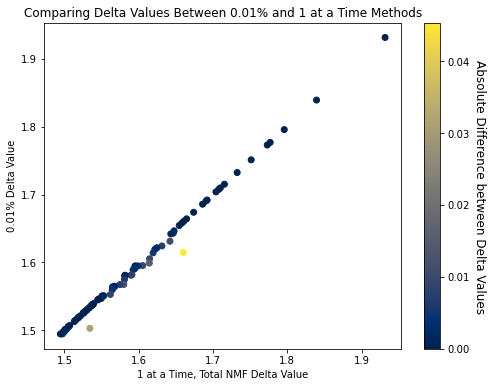

In [26]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

scat = plt.scatter(total_NMF_100_cycles_changes_delta, first_01_added_calls_delta_vals[:100],
            c=np.abs(total_NMF_100_cycles_changes_delta - first_01_added_calls_delta_vals[:100]),
            cmap='cividis')


fig.colorbar(scat)
fig.text(0.87, 0.5, 'Absolute Difference between Delta Values', va='center', rotation=270, fontsize=12)
plt.ylabel('0.01% Delta Value')
plt.xlabel('1 at a Time, Total NMF Delta Value')
plt.title('Comparing Delta Values Between 0.01% and 1 at a Time Methods')

In [35]:
first_01_added_calls_delta_vals[-1000]

0.8844277506083248

Text(0.5, 1.0, 'Delta Values for Added and Removed Calls from Each Cycle\nDelta Fill-in, Fill Size=0.01%')

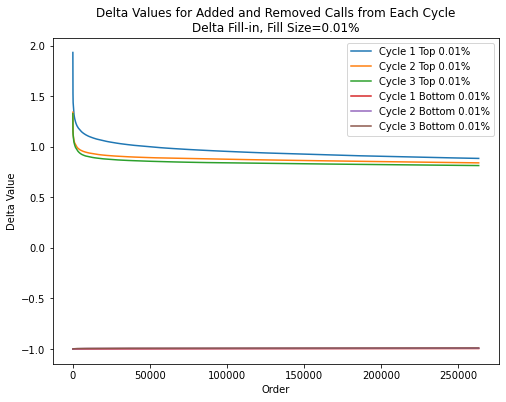

In [16]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(first_01_added_calls_delta_vals)), first_01_added_calls_delta_vals)
plt.plot(np.arange(len(second_01_added_calls_delta_vals)), second_01_added_calls_delta_vals)
plt.plot(np.arange(len(third_01_added_calls_delta_vals)), third_01_added_calls_delta_vals)

plt.plot(np.arange(len(first_01_removed_calls_delta_vals)), first_01_removed_calls_delta_vals)
plt.plot(np.arange(len(second_01_removed_calls_delta_vals)), second_01_removed_calls_delta_vals)
plt.plot(np.arange(len(third_01_removed_calls_delta_vals)), third_01_removed_calls_delta_vals)

plt.legend(['Cycle 1 Top 0.01%', 'Cycle 2 Top 0.01%', 'Cycle 3 Top 0.01%', 'Cycle 1 Bottom 0.01%', 'Cycle 2 Bottom 0.01%', 'Cycle 3 Bottom 0.01%',])

plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Added and Removed Calls from Each Cycle\nDelta Fill-in, Fill Size=0.01%')

In [35]:
np.where(third_01_added_calls_peak_signal==0)[0]

array([  2106,   2935,   2946, ..., 263143, 263204, 263251])

In [32]:
first_01_added_calls_peak_signal.shape

(263286,)

In [33]:
1696/263286

0.006441664197868477

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%')

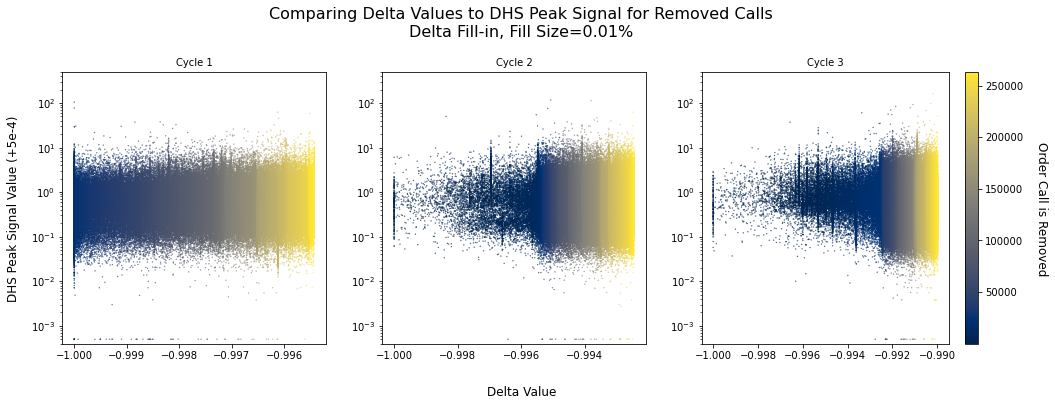

In [47]:
data = [first_01_removed_calls_delta_vals, 
        first_01_removed_calls_peak_signal+0.0005, 
        second_01_removed_calls_delta_vals, 
        second_01_removed_calls_peak_signal+0.0005, 
        third_01_removed_calls_delta_vals, 
        third_01_removed_calls_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.1, c=(np.arange(len(data[2*ind]))+1), cmap='cividis')
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_xlim([0.001, 200])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('log')

fig.colorbar(scat, ax=axes[2])
fig.text(0.92, 0.5, 'Order Call is Removed', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [11]:
#finding peak signal values of removed calls
first_01_removed_calls_peak_signal = []
for i, j in zip(first_01_removed_calls_biosample_inds, first_01_removed_calls_DHS_inds):
    first_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
first_01_removed_calls_peak_signal = np.array(first_01_removed_calls_peak_signal)

second_01_removed_calls_peak_signal = []
for i, j in zip(second_01_removed_calls_biosample_inds, second_01_removed_calls_DHS_inds):
    second_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
second_01_removed_calls_peak_signal = np.array(second_01_removed_calls_peak_signal)
    
third_01_removed_calls_peak_signal = []
for i, j in zip(third_01_removed_calls_biosample_inds, third_01_removed_calls_DHS_inds):
    third_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
third_01_removed_calls_peak_signal = np.array(third_01_removed_calls_peak_signal)

In [12]:
first_01_removed_calls_average_peak_signal = average_peak_signal[first_01_removed_calls_DHS_inds]
second_01_removed_calls_average_peak_signal = average_peak_signal[second_01_removed_calls_DHS_inds]
third_01_removed_calls_average_peak_signal = average_peak_signal[third_01_removed_calls_DHS_inds]

NameError: name 'average_peak_signal' is not defined

In [12]:
#finding average signal value of DHS of removed calls
first_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[first_01_removed_calls_DHS_inds]['mean_signal'])
second_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[second_01_removed_calls_DHS_inds]['mean_signal'])
third_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[third_01_removed_calls_DHS_inds]['mean_signal'])

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%, Subset by Every 50th Removed Call')

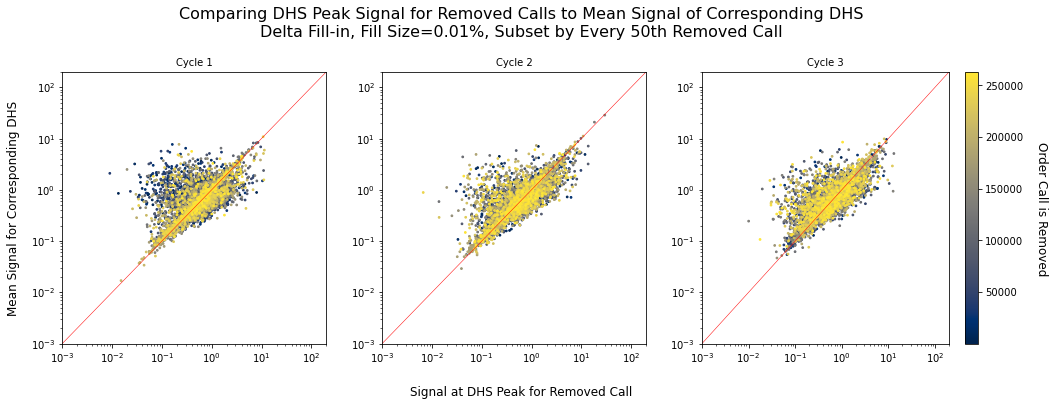

In [45]:
data = [first_01_removed_calls_peak_signal, 
        first_01_removed_calls_DHS_mean_signal, 
        second_01_removed_calls_peak_signal, 
        second_01_removed_calls_DHS_mean_signal, 
        third_01_removed_calls_peak_signal, 
        third_01_removed_calls_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][::50], data[(2*ind)+1][::50], c=(np.arange(len(data[2*ind]))+1)[::50], s=3, cmap='cividis')
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
fig.colorbar(scat, ax=axes[2])
fig.text(0.92, 0.5, 'Order Call is Removed', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Mean Signal for Corresponding DHS', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%, Subset by Every 50th Removed Call', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

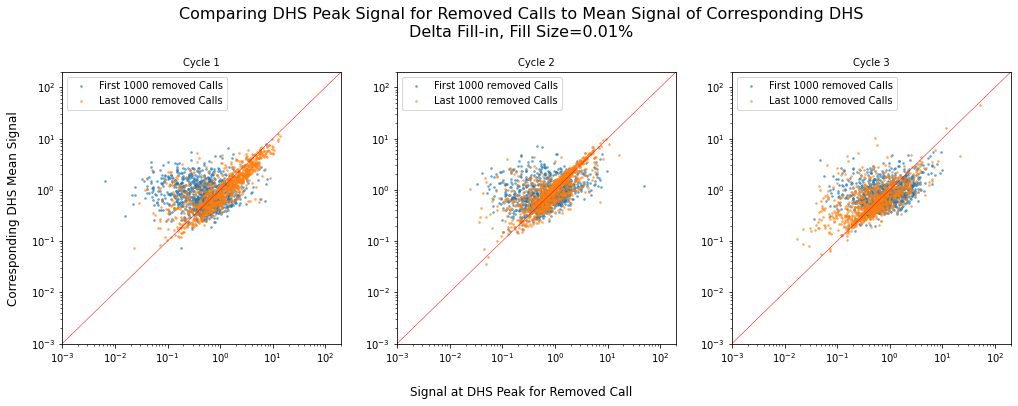

In [13]:
data = [first_01_removed_calls_peak_signal, 
        first_01_removed_calls_DHS_mean_signal, 
        second_01_removed_calls_peak_signal, 
        second_01_removed_calls_DHS_mean_signal, 
        third_01_removed_calls_peak_signal, 
        third_01_removed_calls_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [14]:
#finding peak signal values of added calls
first_01_added_calls_peak_signal = []
for i, j in zip(first_01_added_calls_biosample_inds, first_01_added_calls_DHS_inds):
    first_01_added_calls_peak_signal.append(DHS_peak_signal_array[i, j])
first_01_added_calls_peak_signal = np.array(first_01_added_calls_peak_signal)

second_01_added_calls_peak_signal = []
for i, j in zip(second_01_added_calls_biosample_inds, second_01_added_calls_DHS_inds):
    second_01_added_calls_peak_signal.append(DHS_peak_signal_array[i, j])
second_01_added_calls_peak_signal = np.array(second_01_added_calls_peak_signal)
    
third_01_added_calls_peak_signal = []
for i, j in zip(third_01_added_calls_biosample_inds, third_01_added_calls_DHS_inds):
    third_01_added_calls_peak_signal.append(DHS_peak_signal_array[i, j])
third_01_added_calls_peak_signal = np.array(third_01_added_calls_peak_signal)

In [12]:
#maybe average peak signals across DHSs such that we compare to average peak signal
#also look at max signal df
average_peak_signal = np.mean(DHS_peak_signal_array, axis=0)
print(average_peak_signal.shape)
average_max_signal = np.mean(DHS_max_signal_array, axis=0)
print(average_max_signal.shape)

(3591898,)


In [13]:
first_01_added_calls_average_peak_signal = average_peak_signal[first_01_added_calls_DHS_inds]
second_01_added_calls_average_peak_signal = average_peak_signal[second_01_added_calls_DHS_inds]
third_01_added_calls_average_peak_signal = average_peak_signal[third_01_added_calls_DHS_inds]

In [15]:
#finding average signal value of added calls
first_01_added_calls_DHS_mean_signal = np.array(DHS_metadata.loc[first_01_added_calls_DHS_inds]['mean_signal'])
second_01_added_calls_DHS_mean_signal = np.array(DHS_metadata.loc[second_01_added_calls_DHS_inds]['mean_signal'])
third_01_added_calls_DHS_mean_signal = np.array(DHS_metadata.loc[third_01_added_calls_DHS_inds]['mean_signal'])

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Added Calls\nDelta Fill-in, Fill Size=0.01%')

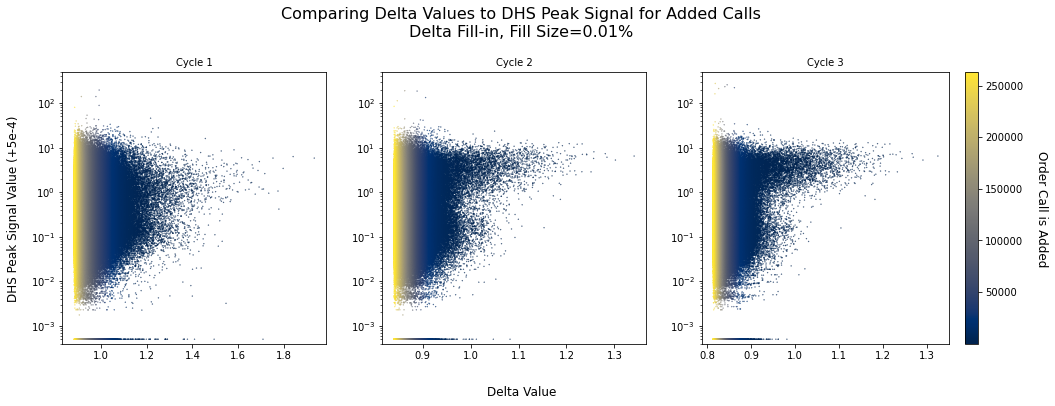

In [50]:
data = [first_01_added_calls_delta_vals, 
        first_01_added_calls_peak_signal+0.0005, 
        second_01_added_calls_delta_vals, 
        second_01_added_calls_peak_signal+0.0005, 
        third_01_added_calls_delta_vals, 
        third_01_added_calls_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.1, c=(np.arange(len(data[2*ind]))+1), cmap='cividis')
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_xlim([0.001, 200])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('symlog')

fig.colorbar(scat, ax=axes[2])
fig.text(0.92, 0.5, 'Order Call is Added', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Added Calls\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added Calls to Mean Peak Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

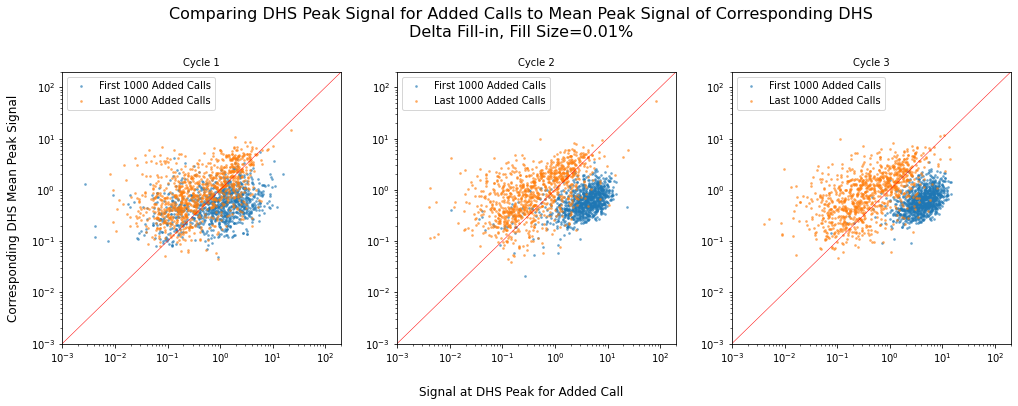

In [26]:
data = [first_01_added_calls_peak_signal, 
        first_01_added_calls_average_peak_signal, 
        second_01_added_calls_peak_signal, 
        second_01_added_calls_average_peak_signal, 
        third_01_added_calls_peak_signal, 
        third_01_added_calls_average_peak_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Peak Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls to Mean Peak Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added Calls to Mean Peak Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%, Subset by Every 50th Added Call')

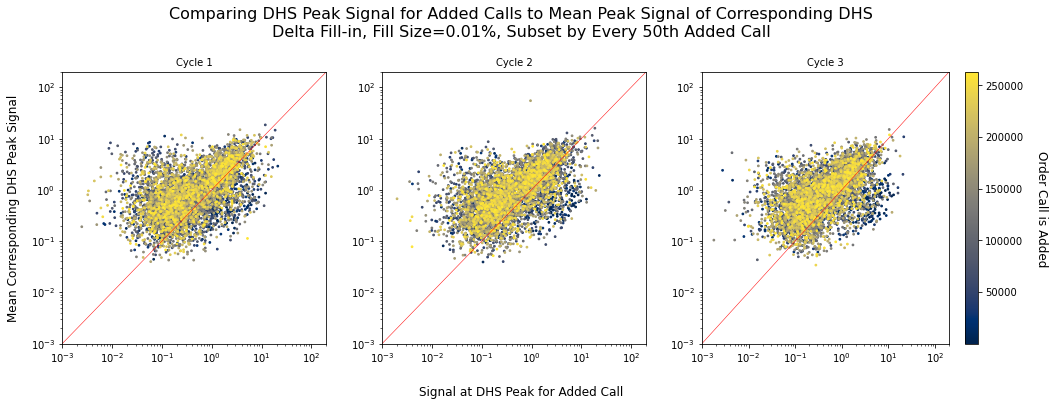

In [14]:
data = [first_01_added_calls_peak_signal, 
        first_01_added_calls_average_peak_signal, 
        second_01_added_calls_peak_signal, 
        second_01_added_calls_average_peak_signal, 
        third_01_added_calls_peak_signal, 
        third_01_added_calls_average_peak_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][::50], data[(2*ind)+1][::50], c=(np.arange(len(data[2*ind]))+1)[::50], s=3, cmap='cividis')
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
fig.colorbar(scat, ax=axes[2])
fig.text(0.92, 0.5, 'Order Call is Added', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Mean Corresponding DHS Peak Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls to Mean Peak Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%, Subset by Every 50th Added Call', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

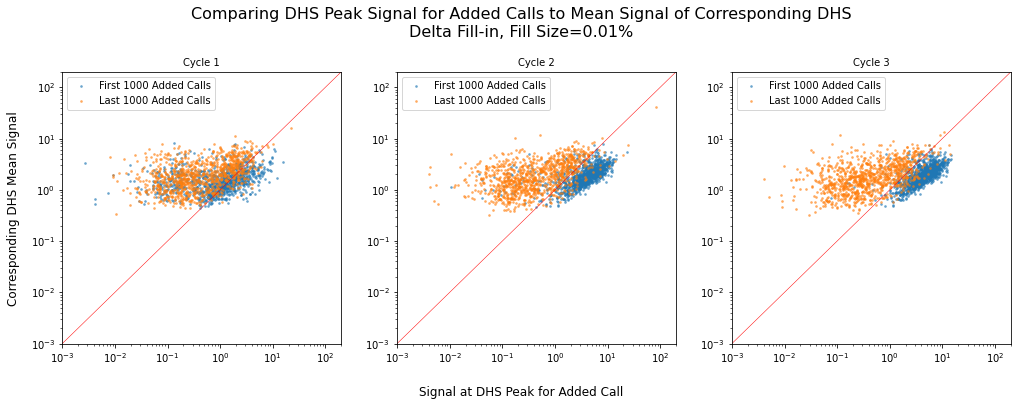

In [17]:
data = [first_01_added_calls_peak_signal, 
        first_01_added_calls_DHS_mean_signal, 
        second_01_added_calls_peak_signal, 
        second_01_added_calls_DHS_mean_signal, 
        third_01_added_calls_peak_signal, 
        third_01_added_calls_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%, Subset by Every 50th Added Call')

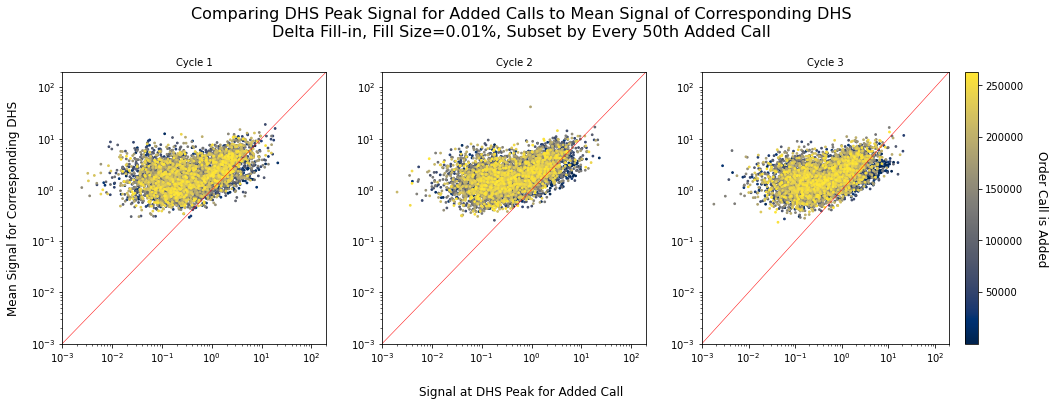

In [28]:
data = [first_01_added_calls_peak_signal, 
        first_01_added_calls_DHS_mean_signal, 
        second_01_added_calls_peak_signal, 
        second_01_added_calls_DHS_mean_signal, 
        third_01_added_calls_peak_signal, 
        third_01_added_calls_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][::50], data[(2*ind)+1][::50], c=(np.arange(len(data[2*ind]))+1)[::50], s=3, cmap='cividis')
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
fig.colorbar(scat, ax=axes[2])
fig.text(0.92, 0.5, 'Order Call is Added', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Mean Signal for Corresponding DHS', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%, Subset by Every 50th Added Call', fontsize=16, x=0.5, y=1.06)

In [12]:
original_decomp_Mixture_top_comps = np.argmax(decomp_Mixture, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps = np.argmax(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)

In [13]:
#filtering out indices where all comps=0, all delta 0.0001
new_decomp_Mixture_all_delta_0001_1_cycle_sum = np.sum(new_decomp_Mixture_all_delta_0001_1_cycle, axis=0)
new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_1_cycle_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_1_cycle_top_comps)

new_decomp_Mixture_all_delta_0001_2_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_2_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_2_cycles_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_2_cycles_top_comps)

new_decomp_Mixture_all_delta_0001_3_cycles_sum = np.sum(new_decomp_Mixture_all_delta_0001_3_cycles, axis=0)
new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered = np.where(new_decomp_Mixture_all_delta_0001_3_cycles_sum==0, np.nan, new_decomp_Mixture_all_delta_0001_3_cycles_top_comps)

In [14]:
#For each cycle, collecting information about the DHSs that belong to each component
DHSs_for_each_comp_0_cycles = []
DHSs_for_each_comp_identifiers_0_cycles = []
DHSs_for_each_comp_mean_comp_signal_0_cycles = []
DHSs_for_each_comp_numsamples_0_cycles = []
for comp in range(16):
    top_comp_dhss = np.where(original_decomp_Mixture_top_comps==comp)
    DHSs_for_each_comp_0_cycles.append(top_comp_dhss)
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_0_cycles.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_0_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_0_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_1_cycle = []
DHSs_for_each_comp_identifiers_1_cycle = []
DHSs_for_each_comp_mean_comp_signal_1_cycle = []
DHSs_for_each_comp_numsamples_1_cycle = []
DHSs_dropped_cycle_1 = []
DHSs_added_cycle_1 = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered==comp)
    DHSs_for_each_comp_1_cycle.append(top_comp_dhss)
    DHSs_added_cycle_1.append(np.sort(np.array(list(set(DHSs_for_each_comp_1_cycle[comp][0]) - set(DHSs_for_each_comp_0_cycles[comp][0])))))
    DHSs_dropped_cycle_1.append(np.sort(np.array(list(set(DHSs_for_each_comp_0_cycles[comp][0]) - set(DHSs_for_each_comp_1_cycle[comp][0])))))
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_1_cycle.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_1_cycle.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_1_cycle.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_2_cycles = []
DHSs_for_each_comp_identifiers_2_cycles = []
DHSs_for_each_comp_mean_comp_signal_2_cycles = []
DHSs_for_each_comp_numsamples_2_cycles = []
DHSs_dropped_cycle_2 = []
DHSs_added_cycle_2 = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered==comp)
    DHSs_for_each_comp_2_cycles.append(top_comp_dhss)
    DHSs_added_cycle_2.append(np.sort(np.array(list(set(DHSs_for_each_comp_2_cycles[comp][0]) - set(DHSs_for_each_comp_1_cycle[comp][0])))))
    DHSs_dropped_cycle_2.append(np.sort(np.array(list(set(DHSs_for_each_comp_1_cycle[comp][0]) - set(DHSs_for_each_comp_2_cycles[comp][0])))))
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_2_cycles.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_2_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_2_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_for_each_comp_3_cycles = []
DHSs_for_each_comp_identifiers_3_cycles = []
DHSs_for_each_comp_mean_comp_signal_3_cycles = []
DHSs_for_each_comp_numsamples_3_cycles = []
DHSs_dropped_cycle_3 = []
DHSs_added_cycle_3 = []
for comp in range(16):
    top_comp_dhss = np.where(new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered==comp)
    DHSs_for_each_comp_3_cycles.append(top_comp_dhss)
    DHSs_added_cycle_3.append(np.sort(np.array(list(set(DHSs_for_each_comp_3_cycles[comp][0]) - set(DHSs_for_each_comp_2_cycles[comp][0])))))
    DHSs_dropped_cycle_3.append(np.sort(np.array(list(set(DHSs_for_each_comp_2_cycles[comp][0]) - set(DHSs_for_each_comp_3_cycles[comp][0])))))
    numsamples = DHS_metadata.loc[top_comp_dhss]['numsamples'].astype(int)
    DHSs_for_each_comp_numsamples_3_cycles.append(list(numsamples))
    identifiers = DHS_metadata.loc[top_comp_dhss]['identifier'].astype(str)
    DHSs_for_each_comp_identifiers_3_cycles.append(identifiers)
    DHSs_for_each_comp_mean_comp_signal_3_cycles.append(list(all_comps_average_signal.loc[identifiers]['comp' + str(comp) + ' mean']))
    
DHSs_added_cycle_1_identifiers = []
DHSs_added_cycle_2_identifiers = []
DHSs_added_cycle_3_identifiers = []
for i in range(16):
    DHSs_added_cycle_1_identifiers.append(DHS_metadata.loc[DHSs_added_cycle_1[i]]['identifier'])
    DHSs_added_cycle_2_identifiers.append(DHS_metadata.loc[DHSs_added_cycle_2[i]]['identifier'])
    DHSs_added_cycle_3_identifiers.append(DHS_metadata.loc[DHSs_added_cycle_3[i]]['identifier'])

In [28]:
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_1_cycle_CT20220201.pickle', 'rb')
NMF_fill_in_diff_flat_all_delta_0001_1_cycle_CT20220201=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_2_cycles_CT20220201.pickle', 'rb')
NMF_fill_in_diff_flat_all_delta_0001_2_cycles_CT20220201=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_3_cycles_CT20220201.pickle', 'rb')
NMF_fill_in_diff_flat_all_delta_0001_3_cycles_CT20220201=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_1_cycle_CT20220201.pickle', 'rb')
NMF_fill_in_sorted_diff_flat_all_delta_0001_1_cycle_CT20220201=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_2_cycles_CT20220201.pickle', 'rb')
NMF_fill_in_sorted_diff_flat_all_delta_0001_2_cycles_CT20220201=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_3_cycles_CT20220201.pickle', 'rb')
NMF_fill_in_sorted_diff_flat_all_delta_0001_3_cycles_CT20220201=pickle.load(pickle_in)

In [41]:
biosample_all_info_df_sorted_biosample_num = df.sort_values(['library order'])
biosample_spot_scores = np.array(biosample_all_info_df_sorted_biosample_num['DCC SPOT score'].astype(float))
biosample_DHSs_in_index = np.array(biosample_all_info_df_sorted_biosample_num['DHSs in Index'].astype(int))
biosample_reads_used = np.array(biosample_all_info_df_sorted_biosample_num['Reads used'].astype(int))
biosample_duplication_rate = np.array(extra_biosample_df['duplication rate'])

NameError: name 'df' is not defined

In [ ]:
#plotting order in which biosamples 

In [16]:
#finding the biosamples that are most affected by dropped biosample-DHS interactions

#dhss out of order but that is fine for this analysis
dhs_array_top_10_percent = dhs_array[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent = updated_dhs_array_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent = updated_dhs_array_all_delta_0001_2_cycles[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent = updated_dhs_array_all_delta_0001_3_cycles[:, top_10_percent_DHSs_inds]

dhs_array_top_10_percent_sum_across_dhs = np.sum(dhs_array_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_across_dhs = np.sum(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_across_dhs = np.sum(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_sum_across_dhs = np.sum(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent, axis=1)

net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0 = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_across_dhs - dhs_array_top_10_percent_sum_across_dhs
# net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_0 = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_across_dhs - dhs_array_top_10_percent_sum_across_dhs
# net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_0 = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_sum_across_dhs - dhs_array_top_10_percent_sum_across_dhs

net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1 = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_across_dhs - updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_across_dhs
net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2 = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_sum_across_dhs - updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_across_dhs

In [17]:
#finding the biosamples that are most affected by dropped biosample-DHS interactions

#splitting net change up into DHSs removed and DHSs added

cycle_1_cycle_0_top_10_percent_diff_array = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent - dhs_array_top_10_percent
cycle_2_cycle_1_top_10_percent_diff_array = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent - updated_dhs_array_all_delta_0001_1_cycle_top_10_percent
cycle_3_cycle_2_top_10_percent_diff_array = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent - updated_dhs_array_all_delta_0001_2_cycles_top_10_percent

cycle_1_cycle_0_top_10_percent_added_dhss = (cycle_1_cycle_0_top_10_percent_diff_array + 1) // 2
cycle_2_cycle_1_top_10_percent_added_dhss = (cycle_2_cycle_1_top_10_percent_diff_array + 1) // 2
cycle_3_cycle_2_top_10_percent_added_dhss = (cycle_3_cycle_2_top_10_percent_diff_array + 1) // 2

cycle_1_cycle_0_top_10_percent_added_dhss_sum = np.sum(cycle_1_cycle_0_top_10_percent_added_dhss, axis=1)
cycle_2_cycle_1_top_10_percent_added_dhss_sum = np.sum(cycle_2_cycle_1_top_10_percent_added_dhss, axis=1)
cycle_3_cycle_2_top_10_percent_added_dhss_sum = np.sum(cycle_3_cycle_2_top_10_percent_added_dhss, axis=1)

cycle_1_cycle_0_top_10_percent_removed_dhss = np.abs(cycle_1_cycle_0_top_10_percent_diff_array - 1) // 2
cycle_2_cycle_1_top_10_percent_removed_dhss = np.abs(cycle_2_cycle_1_top_10_percent_diff_array - 1) // 2
cycle_3_cycle_2_top_10_percent_removed_dhss = np.abs(cycle_3_cycle_2_top_10_percent_diff_array - 1) // 2

cycle_1_cycle_0_top_10_percent_removed_dhss_sum = np.sum(cycle_1_cycle_0_top_10_percent_removed_dhss, axis=1)
cycle_2_cycle_1_top_10_percent_removed_dhss_sum = np.sum(cycle_2_cycle_1_top_10_percent_removed_dhss, axis=1)
cycle_3_cycle_2_top_10_percent_removed_dhss_sum = np.sum(cycle_3_cycle_2_top_10_percent_removed_dhss, axis=1)

In [19]:
#finding percent change in number of DHSs for each biosample
dhs_array_top_10_percent_sum_biosamples = np.sum(dhs_array_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_biosamples = np.sum(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_biosamples = np.sum(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_sum_biosamples = np.sum(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent, axis=1)

percent_change_num_dhss_per_biosample_cycle_1_cycle_0 = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_biosamples / dhs_array_top_10_percent_sum_biosamples
percent_change_num_dhss_per_biosample_cycle_2_cycle_1 = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_biosamples / updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_biosamples
percent_change_num_dhss_per_biosample_cycle_3_cycle_2 = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_sum_biosamples / updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_biosamples

Text(0.5, 1.06, 'Comparing Number of Biosample-DHS Interactions Added to Removed by Fractional Change in Number of DHSs\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

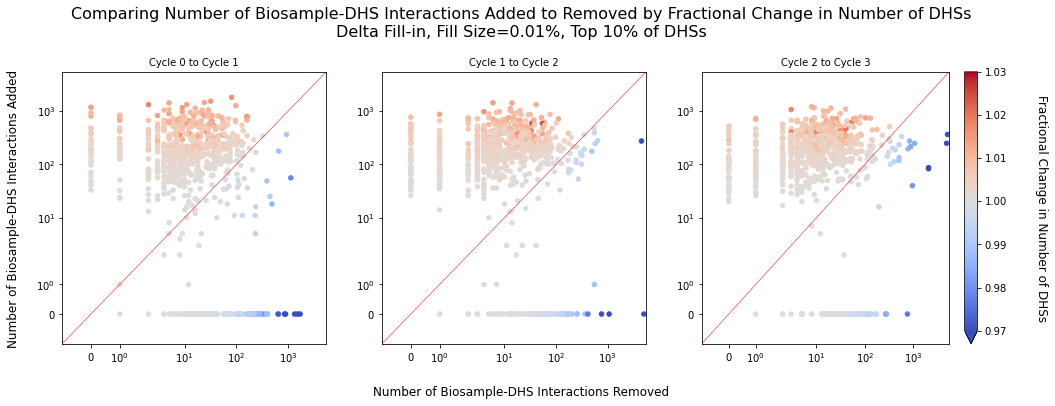

In [67]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, 
        cycle_1_cycle_0_top_10_percent_added_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_removed_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_added_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_removed_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_added_dhss_sum]

percent_change_data = [percent_change_num_dhss_per_biosample_cycle_1_cycle_0, 
                percent_change_num_dhss_per_biosample_cycle_2_cycle_1, 
                percent_change_num_dhss_per_biosample_cycle_3_cycle_2]


plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], c=percent_change_data[ind], s=20, cmap='coolwarm', vmin=0.97, vmax=1.03)#
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, 5500])
    ax.set_ylim([-1, 5500])
    ax.set_xscale('symlog')
    ax.set_yscale('symlog')
    ax.plot(np.arange(5600)-1, np.arange(5600)-1, c='r', linewidth=0.5)
    
    
fig.colorbar(scat, ax=axes[2], extend='min')
fig.text(0.92, 0.5, 'Fractional Change in Number of DHSs', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Number of Biosample-DHS Interactions Removed', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Number of Biosample-DHS Interactions Added', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Number of Biosample-DHS Interactions Added to Removed by Fractional Change in Number of DHSs\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Number of Biosample-DHS Interactions Added to Removed by Duplication Rate\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

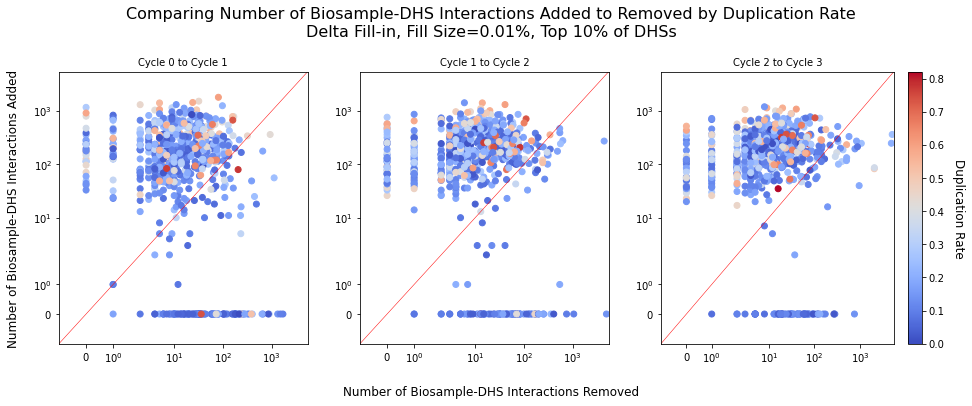

In [89]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, 
        cycle_1_cycle_0_top_10_percent_added_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_removed_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_added_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_removed_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_added_dhss_sum]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], c=biosample_duplication_rate, cmap='coolwarm')
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, 5500])
    ax.set_ylim([-1, 5500])
    ax.set_xscale('symlog')
    ax.set_yscale('symlog')
    ax.plot(np.arange(5600)-1, np.arange(5600)-1, c='r', linewidth=0.5)

fig.colorbar(scat, ax=axes[2])
fig.text(0.9, 0.5, 'Duplication Rate', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Number of Biosample-DHS Interactions Removed', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Number of Biosample-DHS Interactions Added', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Number of Biosample-DHS Interactions Added to Removed by Duplication Rate\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Number of Biosample-DHS Interactions Added to Removed by Number of Reads Used\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

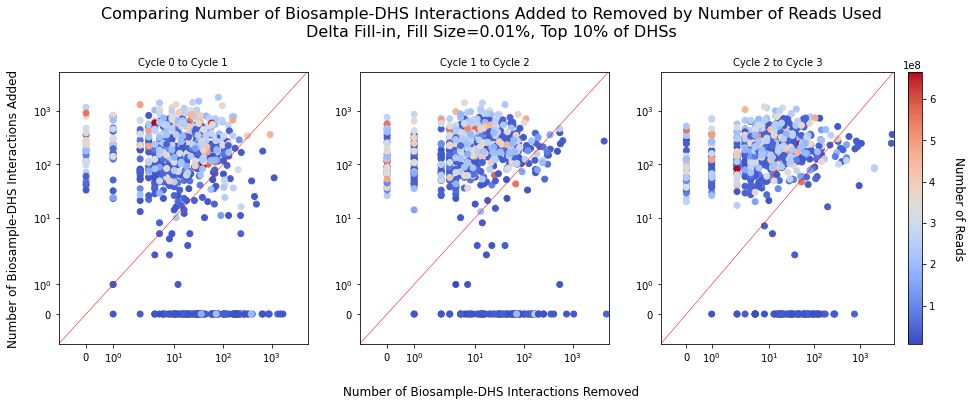

In [88]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, 
        cycle_1_cycle_0_top_10_percent_added_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_removed_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_added_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_removed_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_added_dhss_sum]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], c=biosample_reads_used, cmap='coolwarm')# s=biosample_reads_used/10000000,
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, 5500])
    ax.set_ylim([-1, 5500])
    ax.set_xscale('symlog')
    ax.set_yscale('symlog')
    ax.plot(np.arange(5600)-1, np.arange(5600)-1, c='r', linewidth=0.5)

fig.colorbar(scat, ax=axes[2])
fig.text(0.9, 0.5, 'Number of Reads', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Number of Biosample-DHS Interactions Removed', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Number of Biosample-DHS Interactions Added', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Number of Biosample-DHS Interactions Added to Removed by Number of Reads Used\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Number of Biosample-DHS Interactions Added to Removed by DCC SPOT Score\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

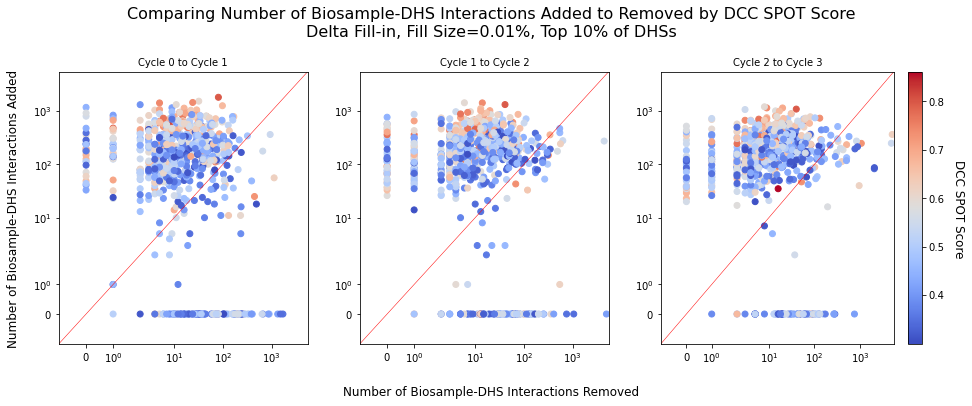

In [87]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, 
        cycle_1_cycle_0_top_10_percent_added_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_removed_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_added_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_removed_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_added_dhss_sum]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], c=biosample_spot_scores, cmap='coolwarm')#, s=biosample_spot_scores*100
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, 5500])
    ax.set_ylim([-1, 5500])
    ax.set_xscale('symlog')
    ax.set_yscale('symlog')
    ax.plot(np.arange(5600)-1, np.arange(5600)-1, c='r', linewidth=0.5)

fig.colorbar(scat, ax=axes[2])
fig.text(0.9, 0.5, 'DCC SPOT Score', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Number of Biosample-DHS Interactions Removed', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Number of Biosample-DHS Interactions Added', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Number of Biosample-DHS Interactions Added to Removed by DCC SPOT Score\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Number of Biosample-DHS Interactions Added to Removed by Number of DHSs in Previous Cycle\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

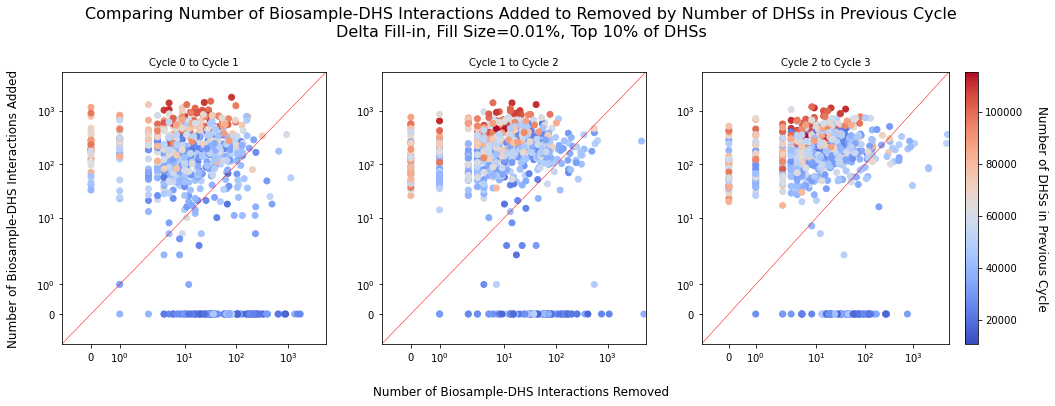

In [84]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, 
        cycle_1_cycle_0_top_10_percent_added_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_removed_dhss_sum, 
        cycle_2_cycle_1_top_10_percent_added_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_removed_dhss_sum, 
        cycle_3_cycle_2_top_10_percent_added_dhss_sum]

num_dhs_data = [dhs_array_top_10_percent_sum_biosamples, 
                updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_biosamples, 
                updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_biosamples]


plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5), gridspec_kw={'width_ratios': [100, 100, 117]})
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], c=num_dhs_data[ind], cmap='coolwarm')
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, 5500])
    ax.set_ylim([-1, 5500])
    ax.set_xscale('symlog')
    ax.set_yscale('symlog')
    ax.plot(np.arange(5600)-1, np.arange(5600)-1, c='r', linewidth=0.5)

fig.colorbar(scat, ax=axes[2])
fig.text(0.92, 0.5, 'Number of DHSs in Previous Cycle', va='center', rotation=270, fontsize=12)
fig.text(0.5, -0.02, 'Number of Biosample-DHS Interactions Removed', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Number of Biosample-DHS Interactions Added', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Number of Biosample-DHS Interactions Added to Removed by Number of DHSs in Previous Cycle\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

In [78]:
most_affected_biosamples_removed_interactions_cycle_3_cycle_2 = np.argsort(cycle_3_cycle_2_top_10_percent_removed_dhss_sum)

Text(0.5, 0.96, 'Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

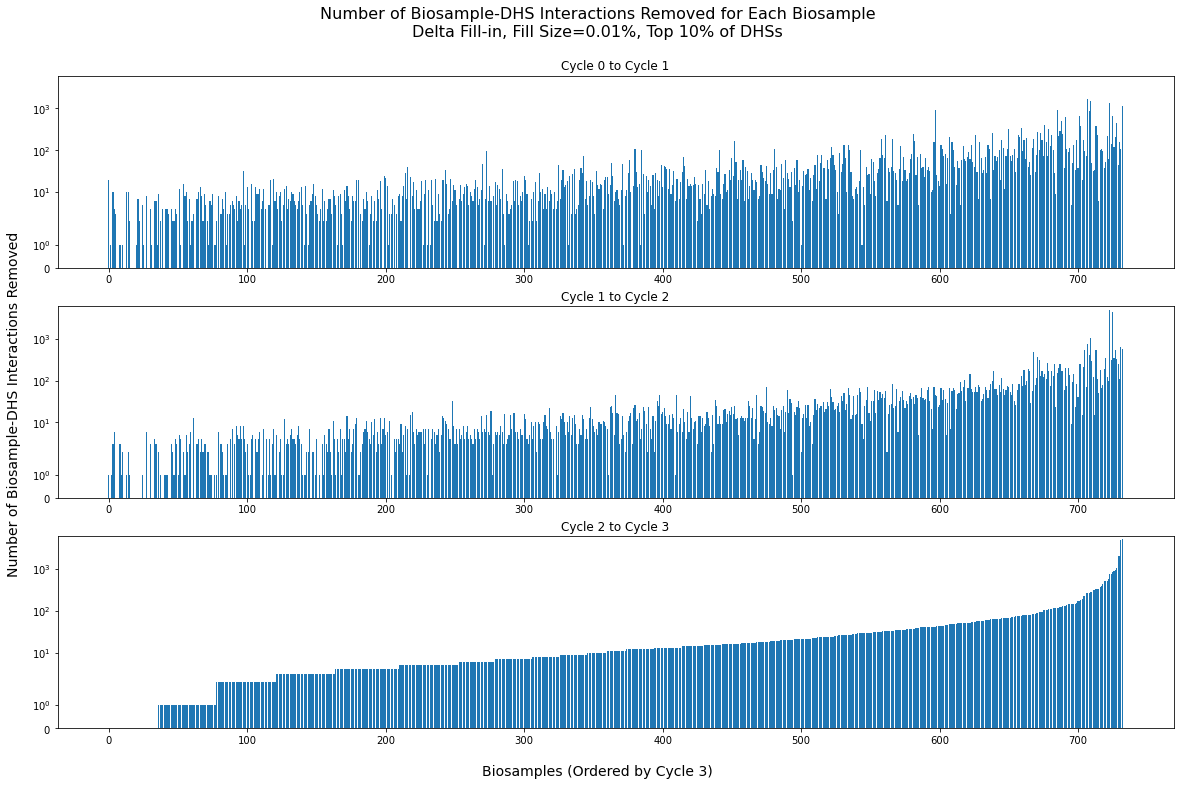

In [85]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum[most_affected_biosamples_removed_interactions_cycle_3_cycle_2], 
        cycle_2_cycle_1_top_10_percent_removed_dhss_sum[most_affected_biosamples_removed_interactions_cycle_3_cycle_2], 
        cycle_3_cycle_2_top_10_percent_removed_dhss_sum[most_affected_biosamples_removed_interactions_cycle_3_cycle_2]]
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(20,12))
fig.patch.set_facecolor('white')

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    c = np.array(['#1f77b4']*733)
#     c[np.where(data[ind]<0)[0]]='#ff7f0e'
    ax.bar(np.arange(733), data[ind], color=c)
    ax.set_ylim([0, 6000])
    ax.set_yscale('symlog')
    ax.set_title(plot_titles[ind], fontsize=12)


fig.text(0.5, 0.07, 'Biosamples (Ordered by Cycle 3)', ha='center', fontsize=14)
fig.text(0.09, 0.5, 'Number of Biosample-DHS Interactions Removed', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=0.96)

Text(0.5, 1.06, 'Duplication Rate Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

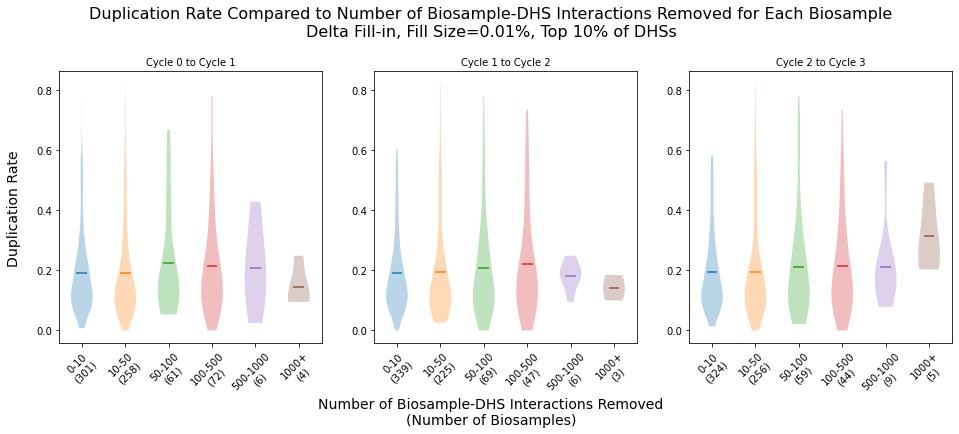

In [57]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, cycle_2_cycle_1_top_10_percent_removed_dhss_sum, cycle_3_cycle_2_top_10_percent_removed_dhss_sum]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    bin_inds_1 = np.where(np.logical_and(np.greater(data[ind], 0), np.less_equal(data[ind], 10)))[0]
    bin_inds_2 = np.where(np.logical_and(np.greater(data[ind], 10), np.less_equal(data[ind], 50)))[0]
    bin_inds_3 = np.where(np.logical_and(np.greater(data[ind], 50), np.less_equal(data[ind], 100)))[0]
    bin_inds_4 = np.where(np.logical_and(np.greater(data[ind], 100), np.less_equal(data[ind], 500)))[0]
    bin_inds_5 = np.where(np.logical_and(np.greater(data[ind], 500), np.less_equal(data[ind], 1000)))[0]
    bin_inds_6 = np.where(np.greater(data[ind], 1000))[0]
    bins = [bin_inds_1, bin_inds_2, bin_inds_3, bin_inds_4, bin_inds_5, bin_inds_6]
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(biosample_duplication_rate[b], positions=[j], showextrema=False, showmeans=True)
#         ax.annotate(str(len(bins[j])), (j-0.15, 0.85))
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xticks([0, 1, 2, 3, 4, 5])
    ax.set_xticklabels(['0-10\n('+str(len(bins[0]))+')', '10-50\n('+str(len(bins[1]))+')', '50-100\n('+str(len(bins[2]))+')', '100-500\n('+str(len(bins[3]))+')', '500-1000\n('+str(len(bins[4]))+')', '1000+\n('+str(len(bins[5]))+')'], rotation=45)
    
fig.text(0.5, -0.1, 'Number of Biosample-DHS Interactions Removed\n(Number of Biosamples)', ha='center', fontsize=14)
fig.text(0.08, 0.5, 'Duplication Rate', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Duplication Rate Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Number of Reads Used Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

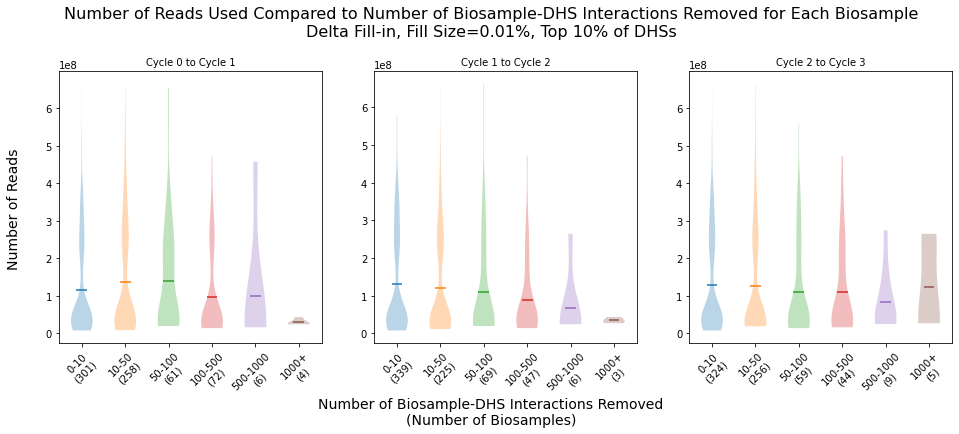

In [58]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, cycle_2_cycle_1_top_10_percent_removed_dhss_sum, cycle_3_cycle_2_top_10_percent_removed_dhss_sum]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    bin_inds_1 = np.where(np.logical_and(np.greater(data[ind], 0), np.less_equal(data[ind], 10)))[0]
    bin_inds_2 = np.where(np.logical_and(np.greater(data[ind], 10), np.less_equal(data[ind], 50)))[0]
    bin_inds_3 = np.where(np.logical_and(np.greater(data[ind], 50), np.less_equal(data[ind], 100)))[0]
    bin_inds_4 = np.where(np.logical_and(np.greater(data[ind], 100), np.less_equal(data[ind], 500)))[0]
    bin_inds_5 = np.where(np.logical_and(np.greater(data[ind], 500), np.less_equal(data[ind], 1000)))[0]
    bin_inds_6 = np.where(np.greater(data[ind], 1000))[0]
    bins = [bin_inds_1, bin_inds_2, bin_inds_3, bin_inds_4, bin_inds_5, bin_inds_6]
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(biosample_reads_used[b], positions=[j], showextrema=False, showmeans=True)
#         ax.annotate(str(len(bins[j])), (j-0.15, 0.85))
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_ylim([0, 800])
    ax.set_xticks([0, 1, 2, 3, 4, 5])
    ax.set_xticklabels(['0-10\n('+str(len(bins[0]))+')', '10-50\n('+str(len(bins[1]))+')', '50-100\n('+str(len(bins[2]))+')', '100-500\n('+str(len(bins[3]))+')', '500-1000\n('+str(len(bins[4]))+')', '1000+\n('+str(len(bins[5]))+')'], rotation=45)
    
fig.text(0.5, -0.1, 'Number of Biosample-DHS Interactions Removed\n(Number of Biosamples)', ha='center', fontsize=14)
fig.text(0.08, 0.5, 'Number of Reads', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of Reads Used Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

In [28]:
dhs_array_top_10_percent_sum_biosamples = np.sum(dhs_array_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_biosamples = np.sum(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_biosamples = np.sum(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent, axis=1)
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_sum_biosamples = np.sum(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent, axis=1)

Text(0.5, 1.06, 'Number of DHSs in Previous Cycle Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

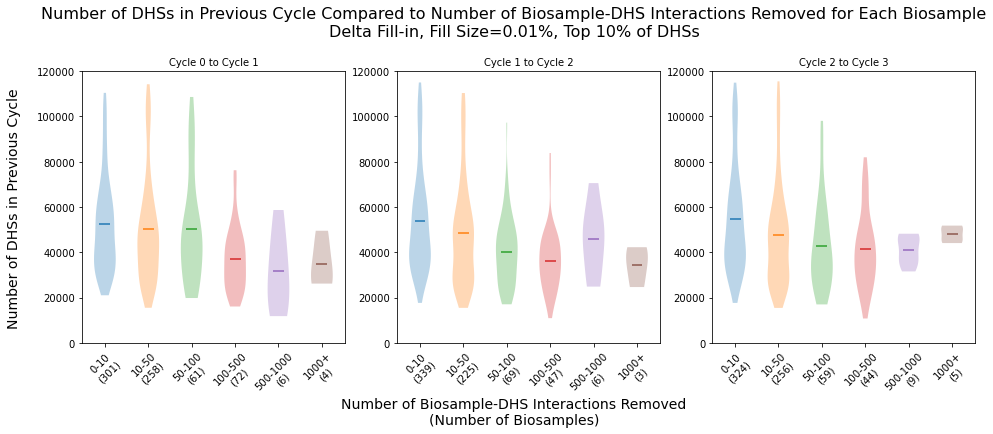

In [60]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, cycle_2_cycle_1_top_10_percent_removed_dhss_sum, cycle_3_cycle_2_top_10_percent_removed_dhss_sum]

num_dhs_data = [dhs_array_top_10_percent_sum_biosamples, updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_sum_biosamples, updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_sum_biosamples]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    bin_inds_1 = np.where(np.logical_and(np.greater(data[ind], 0), np.less_equal(data[ind], 10)))[0]
    bin_inds_2 = np.where(np.logical_and(np.greater(data[ind], 10), np.less_equal(data[ind], 50)))[0]
    bin_inds_3 = np.where(np.logical_and(np.greater(data[ind], 50), np.less_equal(data[ind], 100)))[0]
    bin_inds_4 = np.where(np.logical_and(np.greater(data[ind], 100), np.less_equal(data[ind], 500)))[0]
    bin_inds_5 = np.where(np.logical_and(np.greater(data[ind], 500), np.less_equal(data[ind], 1000)))[0]
    bin_inds_6 = np.where(np.greater(data[ind], 1000))[0]
    bins = [bin_inds_1, bin_inds_2, bin_inds_3, bin_inds_4, bin_inds_5, bin_inds_6]
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(num_dhs_data[ind][b], positions=[j], showextrema=False, showmeans=True)
#         ax.annotate(str(len(bins[j])), (j-0.15, 0.85))
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_ylim([0, 120000])
    ax.set_xticks([0, 1, 2, 3, 4, 5])
    ax.set_xticklabels(['0-10\n('+str(len(bins[0]))+')', '10-50\n('+str(len(bins[1]))+')', '50-100\n('+str(len(bins[2]))+')', '100-500\n('+str(len(bins[3]))+')', '500-1000\n('+str(len(bins[4]))+')', '1000+\n('+str(len(bins[5]))+')'], rotation=45)
    
fig.text(0.5, -0.1, 'Number of Biosample-DHS Interactions Removed\n(Number of Biosamples)', ha='center', fontsize=14)
fig.text(0.06, 0.5, 'Number of DHSs in Previous Cycle', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of DHSs in Previous Cycle Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'SPOT Score Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

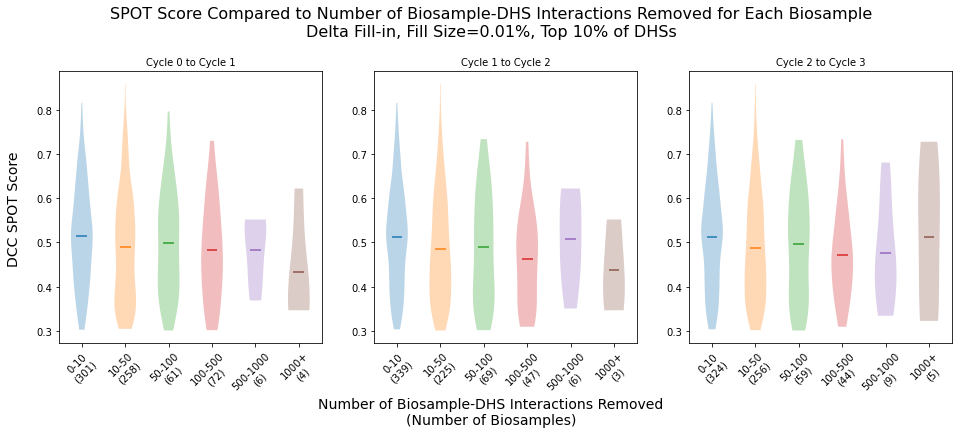

In [61]:
data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, cycle_2_cycle_1_top_10_percent_removed_dhss_sum, cycle_3_cycle_2_top_10_percent_removed_dhss_sum]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    bin_inds_1 = np.where(np.logical_and(np.greater(data[ind], 0), np.less_equal(data[ind], 10)))[0]
    bin_inds_2 = np.where(np.logical_and(np.greater(data[ind], 10), np.less_equal(data[ind], 50)))[0]
    bin_inds_3 = np.where(np.logical_and(np.greater(data[ind], 50), np.less_equal(data[ind], 100)))[0]
    bin_inds_4 = np.where(np.logical_and(np.greater(data[ind], 100), np.less_equal(data[ind], 500)))[0]
    bin_inds_5 = np.where(np.logical_and(np.greater(data[ind], 500), np.less_equal(data[ind], 1000)))[0]
    bin_inds_6 = np.where(np.greater(data[ind], 1000))[0]
    bins = [bin_inds_1, bin_inds_2, bin_inds_3, bin_inds_4, bin_inds_5, bin_inds_6]
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(biosample_spot_scores[b], positions=[j], showextrema=False, showmeans=True)
#         ax.annotate(str(len(bins[j])), (j-0.15, 0.85))
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_ylim([0, 800])
    ax.set_xticks([0, 1, 2, 3, 4, 5])
    ax.set_xticklabels(['0-10\n('+str(len(bins[0]))+')', '10-50\n('+str(len(bins[1]))+')', '50-100\n('+str(len(bins[2]))+')', '100-500\n('+str(len(bins[3]))+')', '500-1000\n('+str(len(bins[4]))+')', '1000+\n('+str(len(bins[5]))+')'], rotation=45)
    
fig.text(0.5, -0.1, 'Number of Biosample-DHS Interactions Removed\n(Number of Biosamples)', ha='center', fontsize=14)
fig.text(0.08, 0.5, 'DCC SPOT Score', va='center', rotation='vertical', fontsize=14)
plt.suptitle('SPOT Score Compared to Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

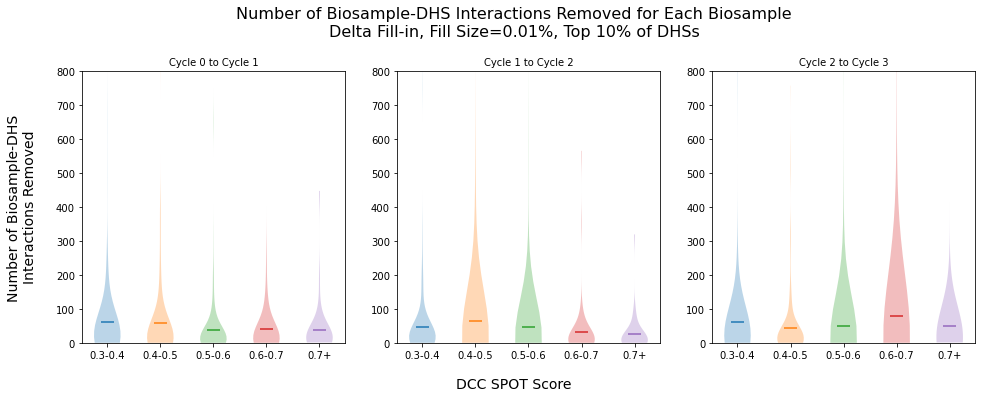

In [115]:
spot_03_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.3), np.less_equal(biosample_spot_scores, 0.4)))[0]
spot_04_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.4), np.less_equal(biosample_spot_scores, 0.5)))[0]
spot_05_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.5), np.less_equal(biosample_spot_scores, 0.6)))[0]
spot_06_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.6), np.less_equal(biosample_spot_scores, 0.7)))[0]
spot_07_bin_inds = np.where(np.greater(biosample_spot_scores, 0.7))[0]

data = [cycle_1_cycle_0_top_10_percent_removed_dhss_sum, cycle_2_cycle_1_top_10_percent_removed_dhss_sum, cycle_3_cycle_2_top_10_percent_removed_dhss_sum]
bins = [spot_03_bin_inds, spot_04_bin_inds, spot_05_bin_inds, spot_06_bin_inds, spot_07_bin_inds]
plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(data[ind][b], positions=[j], showextrema=False, showmeans=True)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_ylim([0, 800])
    ax.set_xticks([0, 1, 2, 3, 4])
    ax.set_xticklabels(['0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7+'])
    
fig.text(0.5, 0.0, 'DCC SPOT Score', ha='center', fontsize=14)
fig.text(0.06, 0.5, 'Number of Biosample-DHS\n    Interactions Removed', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of Biosample-DHS Interactions Removed for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

In [19]:
spot_03_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.3), np.less_equal(biosample_spot_scores, 0.4)))[0]
spot_04_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.4), np.less_equal(biosample_spot_scores, 0.5)))[0]
spot_05_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.5), np.less_equal(biosample_spot_scores, 0.6)))[0]
spot_06_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.6), np.less_equal(biosample_spot_scores, 0.7)))[0]
spot_07_bin_inds = np.where(np.greater(biosample_spot_scores, 0.7))[0]
# spot_08_bin_inds = np.where(np.logical_and(np.greater(biosample_spot_scores, 0.8), np.less_equal(biosample_spot_scores, 0.9)))[0]

In [17]:
most_affected_biosamples_net_change_dhss_cycle_1 = np.argsort(net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0)
most_affected_biosamples_net_change_dhss_cycle_2 = np.argsort(net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1)
most_affected_biosamples_net_change_dhss_cycle_3 = np.argsort(net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2)

In [18]:
data = [net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0, net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1, net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2]
for i, i_0 in zip([most_affected_biosamples_net_change_dhss_cycle_1, most_affected_biosamples_net_change_dhss_cycle_2, most_affected_biosamples_net_change_dhss_cycle_3], range(3)):
    names = list(biosample_all_info_df_sorted_biosample_num.loc[i[:3]]['Biosample name'])
    ids = list(biosample_all_info_df_sorted_biosample_num.loc[i[:3]].index)
    spot = list(biosample_all_info_df_sorted_biosample_num.loc[i[:3]]['DCC SPOT score'])
    for j in [0, 1, 2]:
        print('%s (%s) - SPOT score = %s, Net Change = %s' %(names[j], ids[j], spot[j], data[i_0][ids[j]]))
    print()

SK_N_MC (166) - SPOT score = 0.3501, Net Change = -1716
SK_N_MC (167) - SPOT score = 0.3461, Net Change = -1530
WERI_Rb1 (143) - SPOT score = 0.4131, Net Change = -1341

WERI_Rb1 (143) - SPOT score = 0.4131, Net Change = -4969
WERI_Rb1 (144) - SPOT score = 0.552, Net Change = -4186
SK_N_MC (167) - SPOT score = 0.3461, Net Change = -1059

LNCap (177) - SPOT score = 0.6223, Net Change = -4737
LNCap (176) - SPOT score = 0.5447, Net Change = -4635
HAP1 (700) - SPOT score = 0.322, Net Change = -1986



In [19]:
# plt.rcParams['axes.prop_cycle']

In [95]:
# pd.set_option('display.max_columns', None)
# biosample_all_info_df_sorted_biosample_num

In [124]:
net_negative_inds_1_0 = np.where(net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0<0)[0]
net_negative_inds_2_1 = np.where(net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1<0)[0]
net_negative_inds_3_2 = np.where(net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2<0)[0]

net_positive_inds_1_0 = np.where(net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0>=0)[0]
net_positive_inds_2_1 = np.where(net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1>=0)[0]
net_positive_inds_3_2 = np.where(net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2>=0)[0]

In [125]:
net_negative_cycles = [net_negative_inds_1_0, net_negative_inds_2_1, net_negative_inds_3_2]
net_positive_cycles = [net_positive_inds_1_0, net_positive_inds_2_1, net_positive_inds_3_2]

In [126]:
net_negative_dhss_in_index = []
for i in net_negative_cycles:
    net_negative_dhss_in_index.append(np.array(biosample_all_info_df_sorted_biosample_num.loc[i]['DHSs in Index']))

net_positive_dhss_in_index = []
for i in net_positive_cycles:
    net_positive_dhss_in_index.append(np.array(biosample_all_info_df_sorted_biosample_num.loc[i]['DHSs in Index']))
    
net_negative_spot = []
for i in net_negative_cycles:
    net_negative_spot.append(np.array(biosample_all_info_df_sorted_biosample_num.loc[i]['DCC SPOT score']))

net_positive_spot = []
for i in net_positive_cycles:
    net_positive_spot.append(np.array(biosample_all_info_df_sorted_biosample_num.loc[i]['DCC SPOT score']))
    
net_negative_reads = []
for i in net_negative_cycles:
    net_negative_reads.append(np.array(biosample_all_info_df_sorted_biosample_num.loc[i]['Reads used']))

net_positive_reads = []
for i in net_positive_cycles:
    net_positive_reads.append(np.array(biosample_all_info_df_sorted_biosample_num.loc[i]['Reads used']))

Text(0.5, 1.06, 'Comparing Net Negative and Net Positive Biosamples in Each Cycle\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

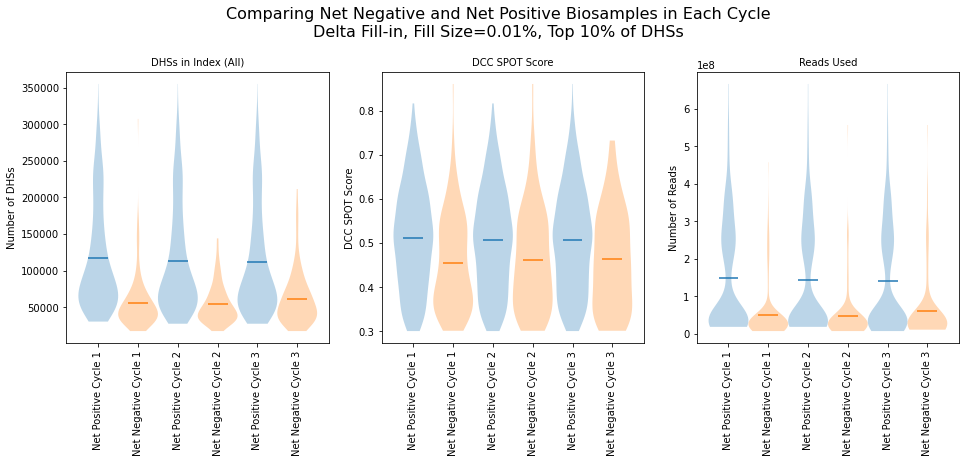

In [127]:
data = [net_positive_dhss_in_index, net_negative_dhss_in_index, net_positive_spot, net_negative_spot, net_positive_reads, net_negative_reads]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')
plot_titles = ['DHSs in Index (All)', 'DCC SPOT Score', 'Reads Used']
ylabels = ['Number of DHSs', 'DCC SPOT Score', 'Number of Reads']

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    for j in range(2):
        ax.violinplot(data[ind*2+j], positions=np.arange(3)+(j/2), showextrema=False, showmeans=True)

    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_ylabel(ylabels[ind])
#     ax.set_ylim([0, 3000])
    ax.set_xticks([0, 0.5, 1, 1.5, 2, 2.5])
    ax.set_xticklabels(['Net Positive Cycle 1', 'Net Negative Cycle 1', 'Net Positive Cycle 2', 'Net Negative Cycle 2', 'Net Positive Cycle 3', 'Net Negative Cycle 3'], rotation=90)
   
# fig.text(0.5, 0.0, 'Biosample Net Change Direction', ha='center', fontsize=14)
# fig.text(0.06, 0.5, 'Absolute Number of Biosample-DHS\n           Interaction Changes', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Comparing Net Negative and Net Positive Biosamples in Each Cycle\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 0.96, 'Net Change in Number of Biosample-DHS Interactions for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

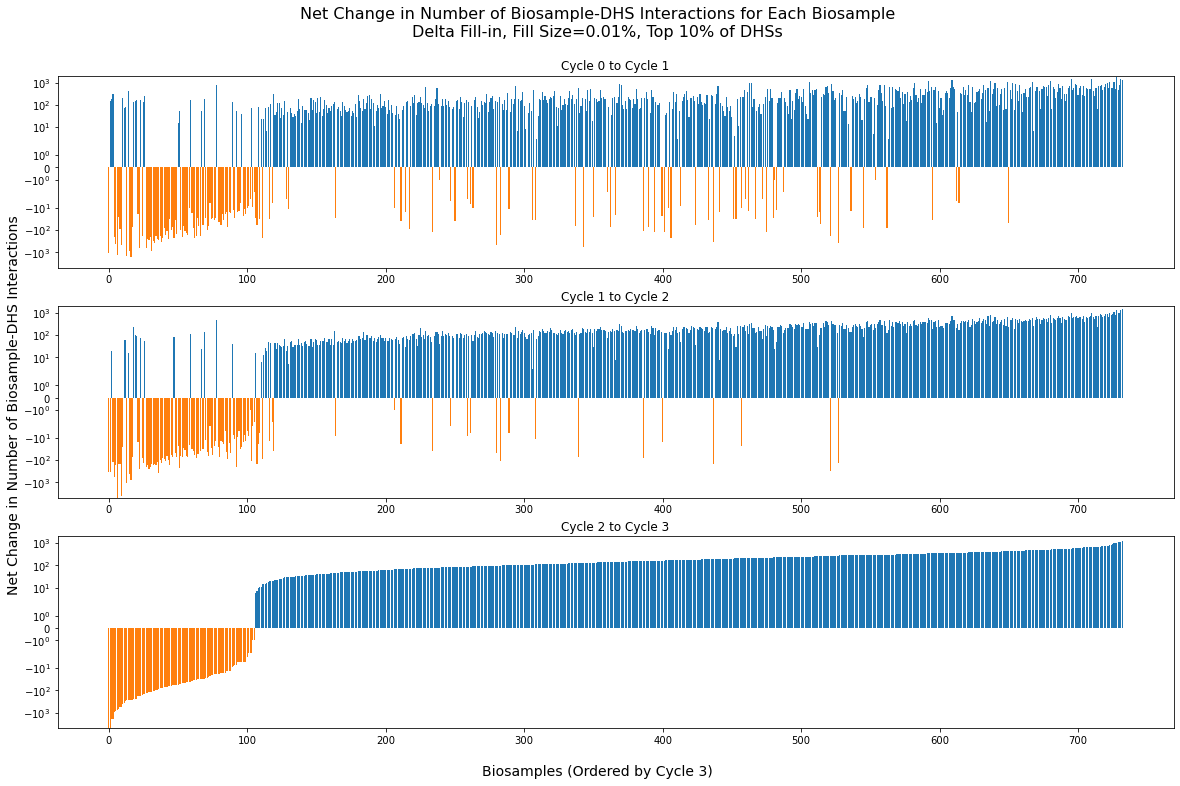

In [55]:
data = [net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0[most_affected_biosamples_net_change_dhss_cycle_3], 
        net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1[most_affected_biosamples_net_change_dhss_cycle_3], 
        net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2[most_affected_biosamples_net_change_dhss_cycle_3]]
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(20,12))
fig.patch.set_facecolor('white')

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    c = np.array(['#1f77b4']*733)
    c[np.where(data[ind]<0)[0]]='#ff7f0e'
    ax.bar(np.arange(733), data[ind], color=c)
    ax.set_ylim([-5000, 2000])
    ax.set_yscale('symlog')
    ax.set_title(plot_titles[ind], fontsize=12)

   
fig.text(0.5, 0.07, 'Biosamples (Ordered by Cycle 3)', ha='center', fontsize=14)
fig.text(0.09, 0.5, 'Net Change in Number of Biosample-DHS Interactions', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Net Change in Number of Biosample-DHS Interactions for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=0.96)

In [21]:
diff_array_cycle_1_cycle_0 = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent - dhs_array_top_10_percent
diff_array_cycle_2_cycle_1 = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent - updated_dhs_array_all_delta_0001_1_cycle_top_10_percent
diff_array_cycle_3_cycle_2 = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent - updated_dhs_array_all_delta_0001_2_cycles_top_10_percent

cycle_1_cycle_0_absolute_changes = np.sum(np.absolute(diff_array_cycle_1_cycle_0), axis=1)
cycle_2_cycle_1_absolute_changes = np.sum(np.absolute(diff_array_cycle_2_cycle_1), axis=1)
cycle_3_cycle_2_absolute_changes = np.sum(np.absolute(diff_array_cycle_3_cycle_2), axis=1)

152
581
116
617
106
627


Text(0.5, 1.06, 'Absolute Number of Biosample-DHS Interaction Changes for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

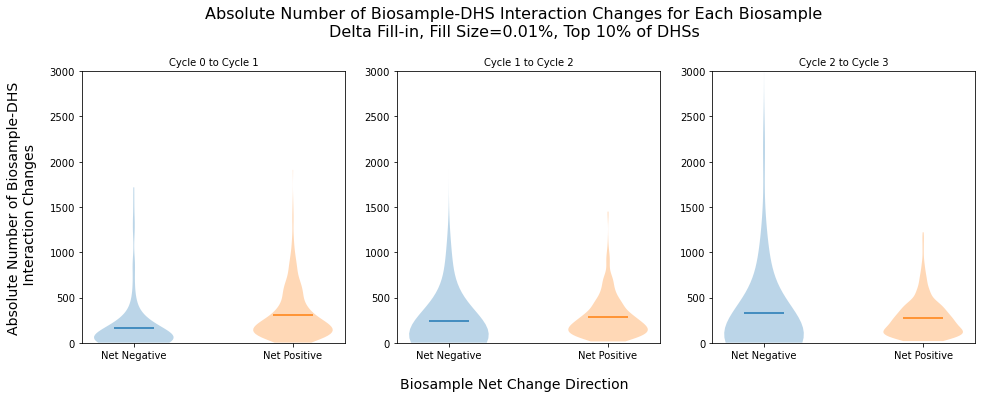

In [50]:
data = [cycle_1_cycle_0_absolute_changes, cycle_2_cycle_1_absolute_changes, cycle_3_cycle_2_absolute_changes]
bins = [net_negative_inds_1_0, net_positive_inds_1_0, net_negative_inds_2_1, net_positive_inds_2_1, net_negative_inds_3_2, net_positive_inds_3_2]
plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']
ylims = [2000, 2000, 2000]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    for b, j in zip(bins[(ind*2):(ind*2)+2], range(2)):
        ax.violinplot(data[ind][b], positions=[j], showextrema=False, showmeans=True)
        print(len(data[ind][b]))
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_ylim([0, 3000])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Net Negative', 'Net Positive'])
   
fig.text(0.5, 0.0, 'Biosample Net Change Direction', ha='center', fontsize=14)
fig.text(0.06, 0.5, 'Absolute Number of Biosample-DHS\n           Interaction Changes', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Absolute Number of Biosample-DHS Interaction Changes for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Net Change in Number of Biosample-DHS Interactions for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

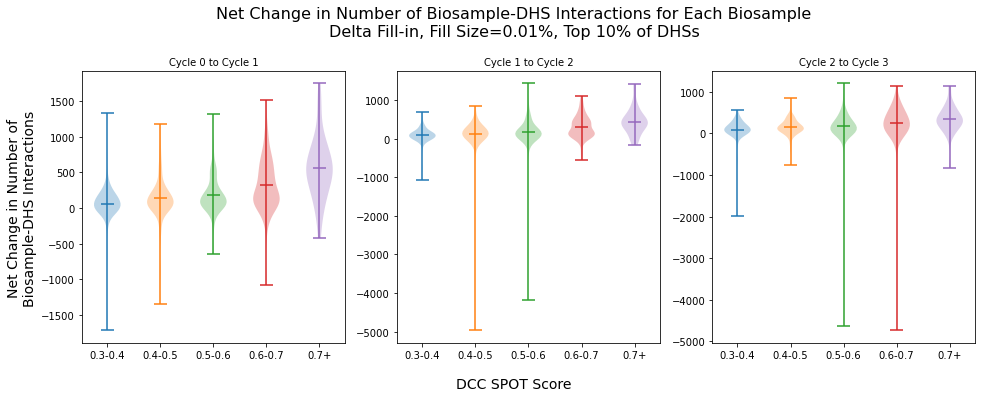

In [25]:
data = [net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0, net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1, net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2]
bins = [spot_03_bin_inds, spot_04_bin_inds, spot_05_bin_inds, spot_06_bin_inds, spot_07_bin_inds]
plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(data[ind][b], positions=[j], showextrema=True, showmeans=True)
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_ylim([-1500, 2000])
    ax.set_xticks([0, 1, 2, 3, 4])
    ax.set_xticklabels(['0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7+'])
   
fig.text(0.5, 0.0, 'DCC SPOT Score', ha='center', fontsize=14)
fig.text(0.06, 0.5, '  Net Change in Number of\nBiosample-DHS Interactions', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Net Change in Number of Biosample-DHS Interactions for Each Biosample\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.07, 'Net Change in Number of Biosample-DHS Interactions for Each Biosample Compared to SPOT Score\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

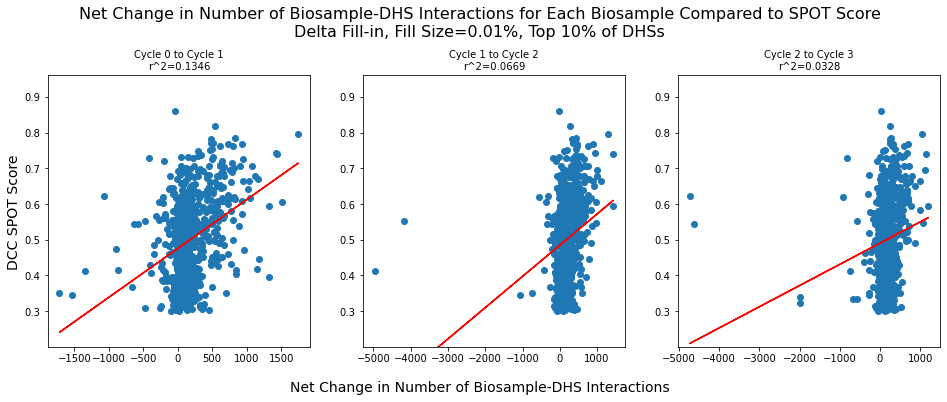

In [29]:
y = biosample_spot_scores
data = [net_change_dhs_nums_per_biosample_top_10_percent_cycle_1_cycle_0, net_change_dhs_nums_per_biosample_top_10_percent_cycle_2_cycle_1, net_change_dhs_nums_per_biosample_top_10_percent_cycle_3_cycle_2]

plot_titles = ['Cycle 0 to Cycle 1', 'Cycle 1 to Cycle 2', 'Cycle 2 to Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
# fig.tight_layout()
# plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    x = data[ind]
    m, b, r, pval, std_err = linregress(x, y)
#     print('r^2=' + str(np.round(r*r, decimals=4)))
    ax.scatter(x, y)
    ax.plot(x, m*x + b, color='r')
    ax.set_ylim([np.min(biosample_spot_scores) - 0.1, np.max(biosample_spot_scores) + 0.1])
    ax.set_title(plot_titles[ind] + '\nr^2=' + str(np.round(r*r, decimals=4)), fontsize=10)
#     ax.set_xlim([-2000, 2000])
   
fig.text(0.5, 0.0, 'Net Change in Number of Biosample-DHS Interactions', ha='center', fontsize=14)
fig.text(0.09, 0.5, 'DCC SPOT Score', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Net Change in Number of Biosample-DHS Interactions for Each Biosample Compared to SPOT Score\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.07)
# plt.xscale('symlog')

In [30]:
#dhss without biosample representation
cycle_1_top_10_percent_dhs_sums = np.sum(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent, axis=0)
cycle_2_top_10_percent_dhs_sums = np.sum(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent, axis=0)
cycle_3_top_10_percent_dhs_sums = np.sum(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent, axis=0)

dhs_dropped_cycle_1_top_10_percent = np.where(cycle_1_top_10_percent_dhs_sums==0)[0]
dhs_dropped_cycle_2_top_10_percent = np.where(cycle_2_top_10_percent_dhs_sums==0)[0]
dhs_dropped_cycle_3_top_10_percent = np.where(cycle_3_top_10_percent_dhs_sums==0)[0]

newly_dropped_cycle_2 = []
for i in dhs_dropped_cycle_2_top_10_percent:
    if i not in dhs_dropped_cycle_1_top_10_percent:
        newly_dropped_cycle_2.append(i)
newly_dropped_cycle_2 = np.array(newly_dropped_cycle_2)

newly_dropped_cycle_3 = []
for i in dhs_dropped_cycle_3_top_10_percent:
    if i not in dhs_dropped_cycle_2_top_10_percent:
        newly_dropped_cycle_3.append(i)
newly_dropped_cycle_3 = np.array(newly_dropped_cycle_3)

dhs_array_top_10_percent_dhss_dropped_cycle_1 = dhs_array_top_10_percent[:, dhs_dropped_cycle_1_top_10_percent]
dhs_array_top_10_percent_dhss_dropped_cycle_2 = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent[:, newly_dropped_cycle_2]
dhs_array_top_10_percent_dhss_dropped_cycle_3 = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent[:, newly_dropped_cycle_3]

dhs_array_top_10_percent_dhss_dropped_cycle_1_summed = np.sum(dhs_array_top_10_percent_dhss_dropped_cycle_1, axis=1)
dhs_array_top_10_percent_dhss_dropped_cycle_2_summed = np.sum(dhs_array_top_10_percent_dhss_dropped_cycle_2, axis=1)
dhs_array_top_10_percent_dhss_dropped_cycle_3_summed = np.sum(dhs_array_top_10_percent_dhss_dropped_cycle_3, axis=1)

In [31]:
most_affected_biosamples_dhss_dropped_cycle_1 = np.argsort(dhs_array_top_10_percent_dhss_dropped_cycle_1_summed)
most_affected_biosamples_dhss_dropped_cycle_2 = np.argsort(dhs_array_top_10_percent_dhss_dropped_cycle_2_summed)
most_affected_biosamples_dhss_dropped_cycle_3 = np.argsort(dhs_array_top_10_percent_dhss_dropped_cycle_3_summed)

In [32]:
data = [dhs_array_top_10_percent_dhss_dropped_cycle_1_summed, dhs_array_top_10_percent_dhss_dropped_cycle_2_summed, dhs_array_top_10_percent_dhss_dropped_cycle_3_summed]
for i, i_0 in zip([most_affected_biosamples_dhss_dropped_cycle_1, most_affected_biosamples_dhss_dropped_cycle_2, most_affected_biosamples_dhss_dropped_cycle_3], range(3)):
    names = list(biosample_all_info_df_sorted_biosample_num.loc[i[-3:]]['Biosample name'])
    ids = list(biosample_all_info_df_sorted_biosample_num.loc[i[-3:]].index)
    spot = list(biosample_all_info_df_sorted_biosample_num.loc[i[-3:]]['DCC SPOT score'])
    for j in [2, 1, 0]:
        print('%s (%s) - SPOT score = %s, Num DHSs = %s' %(names[j], ids[j], spot[j], data[i_0][ids[j]]))
    print()

LNCap (177) - SPOT score = 0.6223, Num DHSs = 873
WERI_Rb1 (143) - SPOT score = 0.4131, Num DHSs = 859
SK_N_MC (167) - SPOT score = 0.3461, Num DHSs = 728

WERI_Rb1 (143) - SPOT score = 0.4131, Num DHSs = 3667
WERI_Rb1 (144) - SPOT score = 0.552, Num DHSs = 3663
CMK (67) - SPOT score = 0.5671, Num DHSs = 403

LNCap (177) - SPOT score = 0.6223, Num DHSs = 4271
LNCap (176) - SPOT score = 0.5447, Num DHSs = 4270
HAP1 (700) - SPOT score = 0.322, Num DHSs = 1865



Text(0.5, 1.06, 'Number of DHSs Present in Each Biosample that were Dropped After Each Cycle\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

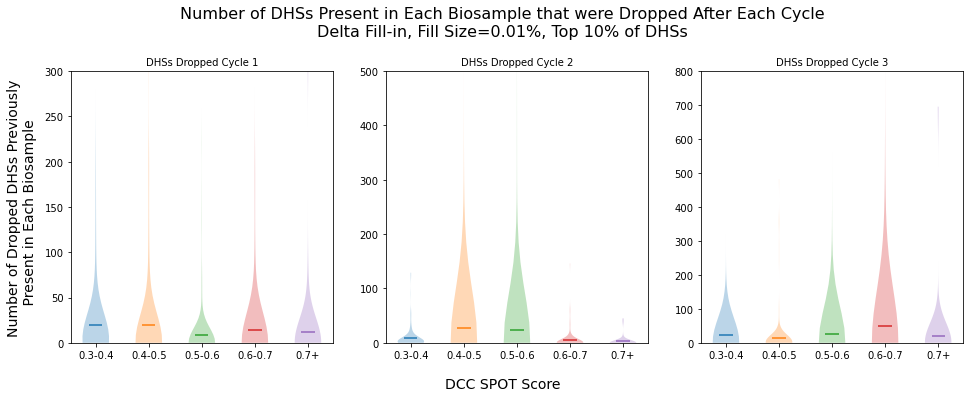

In [38]:
data = [dhs_array_top_10_percent_dhss_dropped_cycle_1_summed, dhs_array_top_10_percent_dhss_dropped_cycle_2_summed, dhs_array_top_10_percent_dhss_dropped_cycle_3_summed]
bins = [spot_03_bin_inds, spot_04_bin_inds, spot_05_bin_inds, spot_06_bin_inds, spot_07_bin_inds]
plot_titles = ['DHSs Dropped Cycle 1', 'DHSs Dropped Cycle 2', 'DHSs Dropped Cycle 3']
cutoff = [300, 500, 800]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    for b, j in zip(bins, range(len(bins))):
        ax.violinplot(data[ind][b], positions=[j], showextrema=False, showmeans=True)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_ylim([0, cutoff[ind]])
    ax.set_xticks([0, 1, 2, 3, 4])
    ax.set_xticklabels(['0.3-0.4', '0.4-0.5', '0.5-0.6', '0.6-0.7', '0.7+'])
   
fig.text(0.5, 0.0, 'DCC SPOT Score', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of Dropped DHSs Previously\n       Present in Each Biosample', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of DHSs Present in Each Biosample that were Dropped After Each Cycle\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.07, 'Number of DHSs Present in Each Biosample that were Dropped After Each Cycle Compared to SPOT Score\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

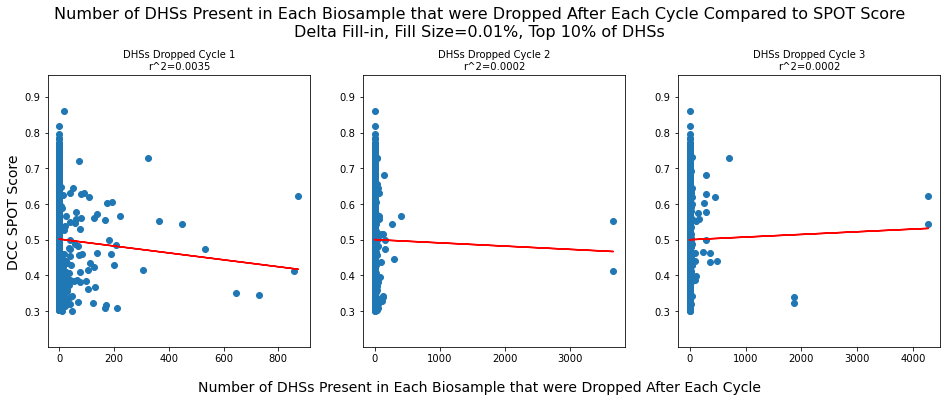

In [70]:
y = biosample_spot_scores
data = [dhs_array_top_10_percent_dhss_dropped_cycle_1_summed, dhs_array_top_10_percent_dhss_dropped_cycle_2_summed, dhs_array_top_10_percent_dhss_dropped_cycle_3_summed]

plot_titles = ['DHSs Dropped Cycle 1', 'DHSs Dropped Cycle 2', 'DHSs Dropped Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16,5))
# fig.tight_layout()
# plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    x = data[ind]
    m, b, r, pval, std_err = linregress(x, y)
#     print('r^2=' + str(np.round(r*r, decimals=4)))
    ax.scatter(x, y)
    ax.plot(x, m*x + b, color='r')
    ax.set_ylim([np.min(biosample_spot_scores) - 0.1, np.max(biosample_spot_scores) + 0.1])
    ax.set_title(plot_titles[ind] + '\nr^2=' + str(np.round(r*r, decimals=4)), fontsize=10)
#     ax.set_xscale('log')
   
fig.text(0.5, 0.0, 'Number of DHSs Present in Each Biosample that were Dropped After Each Cycle', ha='center', fontsize=14)
fig.text(0.09, 0.5, 'DCC SPOT Score', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of DHSs Present in Each Biosample that were Dropped After Each Cycle Compared to SPOT Score\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.07)
# plt.xscale('symlog')

In [13]:
#find the percent of DHSs that are classified by the component with the highest signal value
DHS_metadata = DHS_metadata.sort_values(['ind'])
all_indetifiers = np.array(DHS_metadata['identifier'])
all_comps_average_signal_dhs_ind_ordered = all_comps_average_signal.loc[all_indetifiers]
all_comps_average_signal_dhs_ind_ordered['max signal comp ind'] = all_comps_average_signal_dhs_ind_ordered['max signal'].str.replace('comp', '').str.replace(' mean', '').astype(int)
all_comps_average_signal_dhs_ind_ordered['original top comps'] = original_decomp_Mixture_top_comps
all_comps_average_signal_dhs_ind_ordered['cycle 1 top comps'] = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered
all_comps_average_signal_dhs_ind_ordered['cycle 2 top comps'] = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered
all_comps_average_signal_dhs_ind_ordered['cycle 3 top comps'] = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered

all_comps_average_signal_dhs_ind_ordered['number of columns larger than mean'] = np.array([0]*len(all_comps_average_signal_dhs_ind_ordered))
average_for_each_comp_top_10_percent = []
for i in range(16):
    average_for_each_comp_top_10_percent.append(np.mean(all_comps_average_signal_dhs_ind_ordered[all_comps_average_signal_dhs_ind_ordered['top 10 percent']==True]['comp'+str(i)+' mean']))
    all_comps_average_signal_dhs_ind_ordered.loc[all_comps_average_signal_dhs_ind_ordered['comp'+str(i)+' mean']>average_for_each_comp_top_10_percent[i], 'number of columns larger than mean']+=1

In [14]:
#taking the top 10% of DHSs
all_comps_average_signal_top_10_percent_ordered = all_comps_average_signal_dhs_ind_ordered.loc[top_10_percent_DHSs_identifiers]

In [15]:
mask0 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['original top comps']
mask1 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['cycle 1 top comps']
mask2 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['cycle 2 top comps']
mask3 = all_comps_average_signal_top_10_percent_ordered['max signal comp ind']==all_comps_average_signal_top_10_percent_ordered['cycle 3 top comps']
mask1_baseline = ~all_comps_average_signal_top_10_percent_ordered['cycle 1 top comps'].isnull()
mask2_baseline = ~all_comps_average_signal_top_10_percent_ordered['cycle 2 top comps'].isnull()
mask3_baseline = ~all_comps_average_signal_top_10_percent_ordered['cycle 3 top comps'].isnull()
print(len(all_comps_average_signal_top_10_percent_ordered[mask0 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))
print(len(all_comps_average_signal_top_10_percent_ordered[mask1 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))
print(len(all_comps_average_signal_top_10_percent_ordered[mask2 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))
print(len(all_comps_average_signal_top_10_percent_ordered[mask3 & mask3_baseline]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline]))

0.5002697950769976
0.5007608827452407
0.5013277555474718
0.5009639869043289


In [183]:
# #stratifying by number of components the DHS shows up in
# all_comps_average_signal_top_10_percent_ordered['number of columns larger than mean'] = np.array([0]*len(all_comps_average_signal_top_10_percent_ordered))
# #finding average signal value for each column for top 10% of DHSs
# average_for_each_comp = []
# for i in range(16):
#     average_for_each_comp.append(np.mean(all_comps_average_signal_top_10_percent_ordered['comp'+str(i)+' mean']))
#     all_comps_average_signal_top_10_percent_ordered.loc[all_comps_average_signal_top_10_percent_ordered['comp'+str(i)+' mean']>average_for_each_comp[i], 'number of columns larger than mean']+=1

In [16]:
#stratifying by number of components the DHS shows up in
cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean = []
for i in range(17):
    comp_num_mask = all_comps_average_signal_top_10_percent_ordered['number of columns larger than mean']==i
    cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask0 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
    cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask1 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
    cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask2 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
    cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask3 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)

#DHSs classified in the tissue invariant component   
# mask0_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['original top comps']==0
# mask1_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['cycle 1 top comps']==0
# mask2_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['cycle 2 top comps']==0
# mask3_greater_than_4 = all_comps_average_signal_top_10_percent_ordered['cycle 3 top comps']==0
# for i in range(17):
#     comp_num_mask = all_comps_average_signal_top_10_percent_ordered['number of columns larger than mean']==i
#     cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask0_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
#     cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask1_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
#     cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask2_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)
#     cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean.append(len(all_comps_average_signal_top_10_percent_ordered[mask3_greater_than_4 & mask3_baseline & comp_num_mask]) / len(all_comps_average_signal_top_10_percent_ordered[mask3_baseline & comp_num_mask]) * 100)

Text(0.5, 1.0, 'Percent of DHSs Classified in the "Optimal" Component Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

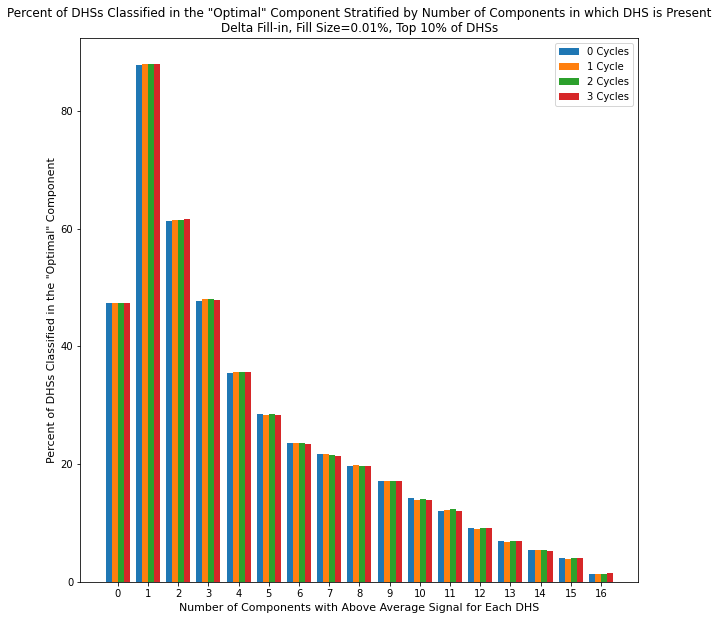

In [17]:
data = [cycle_0_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean, cycle_1_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean, cycle_2_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean, cycle_3_top_10_percent_optimal_comp_percent_stratified_num_comps_larger_mean]
 
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')


plt.bar(np.arange(17)-0.3, data[0], width=0.2)
plt.bar(np.arange(17)-0.1, data[1], width=0.2)
plt.bar(np.arange(17)+0.1, data[2], width=0.2)
plt.bar(np.arange(17)+0.3, data[3], width=0.2)
plt.xticks(np.arange(17), ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16'])
plt.xlabel('Number of Components with Above Average Signal for Each DHS', fontsize=11)
plt.ylabel('Percent of DHSs Classified in the "Optimal" Component', fontsize=11)
plt.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
plt.title('Percent of DHSs Classified in the "Optimal" Component Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [76]:
#finding the number of components each added dhs is present in
cycle_1_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean = []
cycle_2_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean = []
cycle_3_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean = []
for i in range(16):
    DHSs_added_cycle_1_df = all_comps_average_signal_dhs_ind_ordered.loc[DHSs_added_cycle_1_identifiers[i]]
    DHSs_added_cycle_2_df = all_comps_average_signal_dhs_ind_ordered.loc[DHSs_added_cycle_2_identifiers[i]]
    DHSs_added_cycle_3_df = all_comps_average_signal_dhs_ind_ordered.loc[DHSs_added_cycle_3_identifiers[i]]
    DHSs_added_cycle_1_df = DHSs_added_cycle_1_df[DHSs_added_cycle_1_df['top 10 percent']==True]
    DHSs_added_cycle_2_df = DHSs_added_cycle_2_df[DHSs_added_cycle_2_df['top 10 percent']==True]
    DHSs_added_cycle_3_df = DHSs_added_cycle_3_df[DHSs_added_cycle_3_df['top 10 percent']==True]  
    cycle_1_added_dhs_nums_comp_specific = []
    cycle_2_added_dhs_nums_comp_specific = []
    cycle_3_added_dhs_nums_comp_specific = []
    for j in range(17):
        cycle_1_added_dhs_nums_comp_specific.append(len(DHSs_added_cycle_1_df[DHSs_added_cycle_1_df['number of columns larger than mean']==j]))
        cycle_2_added_dhs_nums_comp_specific.append(len(DHSs_added_cycle_2_df[DHSs_added_cycle_2_df['number of columns larger than mean']==j]))
        cycle_3_added_dhs_nums_comp_specific.append(len(DHSs_added_cycle_3_df[DHSs_added_cycle_3_df['number of columns larger than mean']==j]))
    cycle_1_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean.append(cycle_1_added_dhs_nums_comp_specific)
    cycle_2_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean.append(cycle_2_added_dhs_nums_comp_specific)
    cycle_3_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean.append(cycle_3_added_dhs_nums_comp_specific)

Text(0.5, 1.03, 'DHSs Added to Each Component After 3 Cycles Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

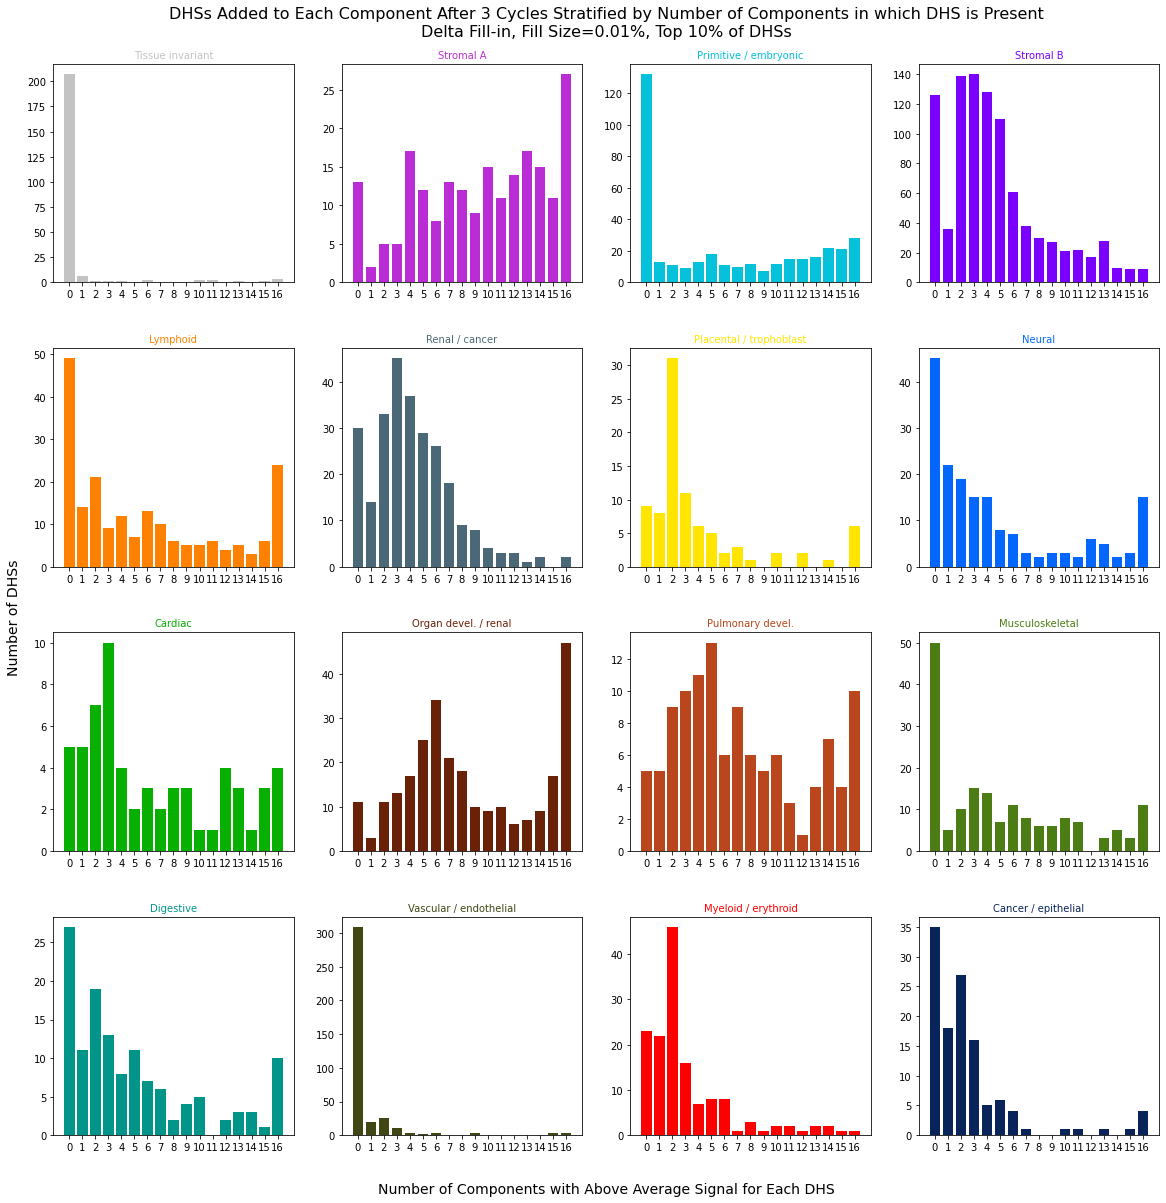

In [92]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    data = [cycle_1_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean[ind], cycle_2_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean[ind], cycle_3_added_top_10_percent_number_of_dhss_stratified_num_comps_larger_mean[ind]]
    ax.bar(np.arange(17), data[2], log=False, color=color[ind])
    
    ax.set_xticks(list(np.arange(17)))
    
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
#     ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
    
fig.text(0.5, 0.0, 'Number of Components with Above Average Signal for Each DHS', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('DHSs Added to Each Component After 3 Cycles Stratified by Number of Components in which DHS is Present\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [116]:
top_10_percent_DHSs_inds

array([     63, 1598356, 1598102, ..., 1357091, 2315567,  761224])

In [123]:
new_decomp_Mixture_all_delta_0001_1_cycle[:, 2315567]

array([0.        , 0.00436984, 0.        , 0.00579168, 0.00509745,
       0.        , 0.        , 0.0003485 , 0.        , 0.00279348,
       0.00145731, 0.        , 0.        , 0.00315534, 0.06611594,
       0.        ])

In [124]:
new_decomp_Mixture_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds]

(16, 359190)

In [ ]:
#quantitatively comparing mixture embeddings
cycle_1_mixture_original_difference = new_decomp_Mixture_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds] - decomp_Mixture[:, top_10_percent_DHSs_inds]
cycle_2_mixture_original_difference = new_decomp_Mixture_all_delta_0001_2_cycles[:, top_10_percent_DHSs_inds] - decomp_Mixture[:, top_10_percent_DHSs_inds]
cycle_3_mixture_original_difference = new_decomp_Mixture_all_delta_0001_3_cycles[:, top_10_percent_DHSs_inds] - decomp_Mixture[:, top_10_percent_DHSs_inds]

In [ ]:
# sum of difference across comps
cycle_1_mixture_original_difference_sum_comps = np.sum(cycle_1_mixture_original_difference, axis=1)
cycle_2_mixture_original_difference_sum_comps = np.sum(cycle_2_mixture_original_difference, axis=1)
cycle_3_mixture_original_difference_sum_comps = np.sum(cycle_3_mixture_original_difference, axis=1)

In [ ]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(np.arange(16)-0.2, cycle_1_mixture_original_difference_sum_comps, width=0.2, color=color, alpha=1)
plt.bar(np.arange(16), cycle_2_mixture_original_difference_sum_comps, width=0.2, color=color, alpha=0.7)
plt.bar(np.arange(16)+0.2, cycle_3_mixture_original_difference_sum_comps, width=0.2, color=color, alpha=0.5)
plt.xticks(np.arange(16), nmf_comps, rotation=90)
plt.xlabel('Component', fontsize=11)
plt.ylabel('Sum of Difference Across Each Component', fontsize=11)
plt.legend(['Cycle 1 - Original', 'Cycle 2 - Original', 'Cycle 3 - Original'])
plt.axhline(y=0, color='k', linewidth=0.5)
plt.title('Sum of Difference Between Each Cycle\'s Mixture and Original Mixture Embeddings Across Each Component\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [24]:
a = np.array([3, 0])
b = np.array([0, 4])
print(a.shape)
print(np.sum(a-b))
print(np.sqrt(np.sum(np.square(a-b))))
print(np.linalg.norm(a-b))

(2,)
-1
5.0
5.0


In [ ]:
#Euclidean distance for each comp
cycle_1_mixture_original_euclidean_distance_comps = np.sqrt(np.sum(np.square(cycle_1_mixture_original_difference), axis=1))
cycle_2_mixture_original_euclidean_distance_comps = np.sqrt(np.sum(np.square(cycle_2_mixture_original_difference), axis=1))
cycle_3_mixture_original_euclidean_distance_comps = np.sqrt(np.sum(np.square(cycle_3_mixture_original_difference), axis=1))

In [39]:
(DHS_metadata[DHS_metadata['component']=='Primitive / embryonic']['numsamples'].astype(int))

3            8
18          69
23          32
24          15
28         156
          ... 
3591825     11
3591830      4
3591847      1
3591865     16
3591866      8
Name: numsamples, Length: 626541, dtype: int64

In [ ]:
fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')

plt.bar(np.arange(16)-0.2, cycle_1_mixture_original_euclidean_distance_comps, width=0.2, color=color, alpha=1)
plt.bar(np.arange(16), cycle_2_mixture_original_euclidean_distance_comps, width=0.2, color=color, alpha=0.7)
plt.bar(np.arange(16)+0.2, cycle_3_mixture_original_euclidean_distance_comps, width=0.2, color=color, alpha=0.5)
plt.xticks(np.arange(16), nmf_comps, rotation=90)
plt.xlabel('Component', fontsize=11)
plt.ylabel('Euclidean Distance Across Each Component', fontsize=11)
plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
plt.title('Euclidean Distance Between Each Cycle\'s Mixture and Original Mixture Embeddings Across Each Component\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [ ]:
#Euclidean distance for each DHS
cycle_1_mixture_original_euclidean_distance_dhss = np.sqrt(np.sum(np.square(cycle_1_mixture_original_difference), axis=0))
cycle_2_mixture_original_euclidean_distance_dhss = np.sqrt(np.sum(np.square(cycle_2_mixture_original_difference), axis=0))
cycle_3_mixture_original_euclidean_distance_dhss = np.sqrt(np.sum(np.square(cycle_3_mixture_original_difference), axis=0))

In [ ]:
nmf_comp_color_dict = {nmf_comps[i]: color[i] for i in range(len(nmf_comps))}

In [ ]:
DHS_metadata_ind_sorted = DHS_metadata.sort_values(['ind'])
DHS_metadata_ind_sorted_top_10_percent = DHS_metadata_ind_sorted.loc[top_10_percent_DHSs_inds]
DHS_metadata_ind_sorted_top_10_percent['numsamples'] = DHS_metadata_ind_sorted_top_10_percent['numsamples'].astype(int)
top_10_percent_sorted_numsamples = np.array(DHS_metadata_ind_sorted_top_10_percent['numsamples'])
top_10_percent_sorted_mean_signal = np.array(DHS_metadata_ind_sorted_top_10_percent['mean_signal'])
top_10_percent_sorted_component = np.array(DHS_metadata_ind_sorted_top_10_percent['component'])
top_10_percent_sorted_component_colors = np.array([nmf_comp_color_dict[i] for i in top_10_percent_sorted_component])

In [ ]:
fig = plt.figure(figsize=(12,12))
fig.patch.set_facecolor('white')

plt.scatter(cycle_1_mixture_original_euclidean_distance_dhss, top_10_percent_sorted_numsamples, c=top_10_percent_sorted_component_colors, s=1)

plt.xlabel('Euclidean Distance Across Each DHS', fontsize=11)
plt.ylabel('Number of Samples', fontsize=11)
plt.xscale('log')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
# plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
plt.title('Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Number of Samples\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    comp_dhss = np.where(top_10_percent_sorted_component==nmf_comps[ind])
    ax.scatter(cycle_1_mixture_original_euclidean_distance_dhss[comp_dhss], top_10_percent_sorted_numsamples[comp_dhss], c=top_10_percent_sorted_component_colors[comp_dhss], s=1)
    
    ax.set_xscale('log')
    ax.set_ylim([0, 750])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

# handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
# fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
# plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
fig.text(0.5, 0.0, 'Euclidean Distance Across Each DHS', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of Samples', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Number of Samples\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs, Stratified by Original DHS Component', fontsize=16, x=0.5, y=1.03)

In [ ]:
fig = plt.figure(figsize=(12,12))
fig.patch.set_facecolor('white')

plt.scatter(cycle_3_mixture_original_euclidean_distance_dhss, top_10_percent_sorted_mean_signal, c=top_10_percent_sorted_component_colors, s=1)

plt.xlabel('Euclidean Distance Across Each DHS', fontsize=11)
plt.ylabel('Mean Signal', fontsize=11)
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
plt.yscale('log')
plt.xscale('log')
plt.title('Euclidean Distance Between Cycle 3 and Original Mixture Embeddings Across Each DHS Compared to Mean Signal\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=12)

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    comp_dhss = np.where(top_10_percent_sorted_component==nmf_comps[ind])
    ax.scatter(cycle_1_mixture_original_euclidean_distance_dhss[comp_dhss], top_10_percent_sorted_mean_signal[comp_dhss], c=top_10_percent_sorted_component_colors[comp_dhss], s=1)
    
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim([1, 550])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

# handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
# fig.legend(handles, nmf_comps, loc = (0.88, 0.73), prop={'size': 7})
# plt.legend(['Cycle 1 to Original', 'Cycle 2 to Original', 'Cycle 3 to Original'])
# plt.axhline(y=0, color='k', linewidth=0.5)
fig.text(0.5, 0.0, 'Euclidean Distance Across Each DHS', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal', va='center', rotation='vertical', fontsize=14)
fig.suptitle('Euclidean Distance Between Cycle 1 and Original Mixture Embeddings Across Each DHS Compared to Mean Signal\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs, Stratified by Original DHS Component', fontsize=16, x=0.5, y=1.03)

In [13]:
#violin plots
cycle_0_top_10_percent_dhss_average_over_all_comps = []
cycle_0_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_0_cycles[i][0]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_0_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_0_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

cycle_1_added_top_10_percent_dhss_average_over_all_comps = []
cycle_1_added_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_added_cycle_1[i]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_1_added_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_1_added_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

cycle_2_added_top_10_percent_dhss_average_over_all_comps = []
cycle_2_added_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_added_cycle_2[i]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_2_added_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_2_added_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

cycle_3_added_top_10_percent_dhss_average_over_all_comps = []
cycle_3_added_top_10_percent_dhss_comp_specific_mean_signal = []
for i in range(16):
    DHSs = DHS_metadata.loc[DHSs_added_cycle_3[i]]['identifier'].astype(str)
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    DHS_signal_values_df = DHS_signal_values_df[DHS_signal_values_df['top 10 percent']==True]
    cycle_3_added_top_10_percent_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    cycle_3_added_top_10_percent_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))


Text(0.5, 1.03, 'Mean Signal Values of DHSs Added to Each Component After 3 Cycles\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

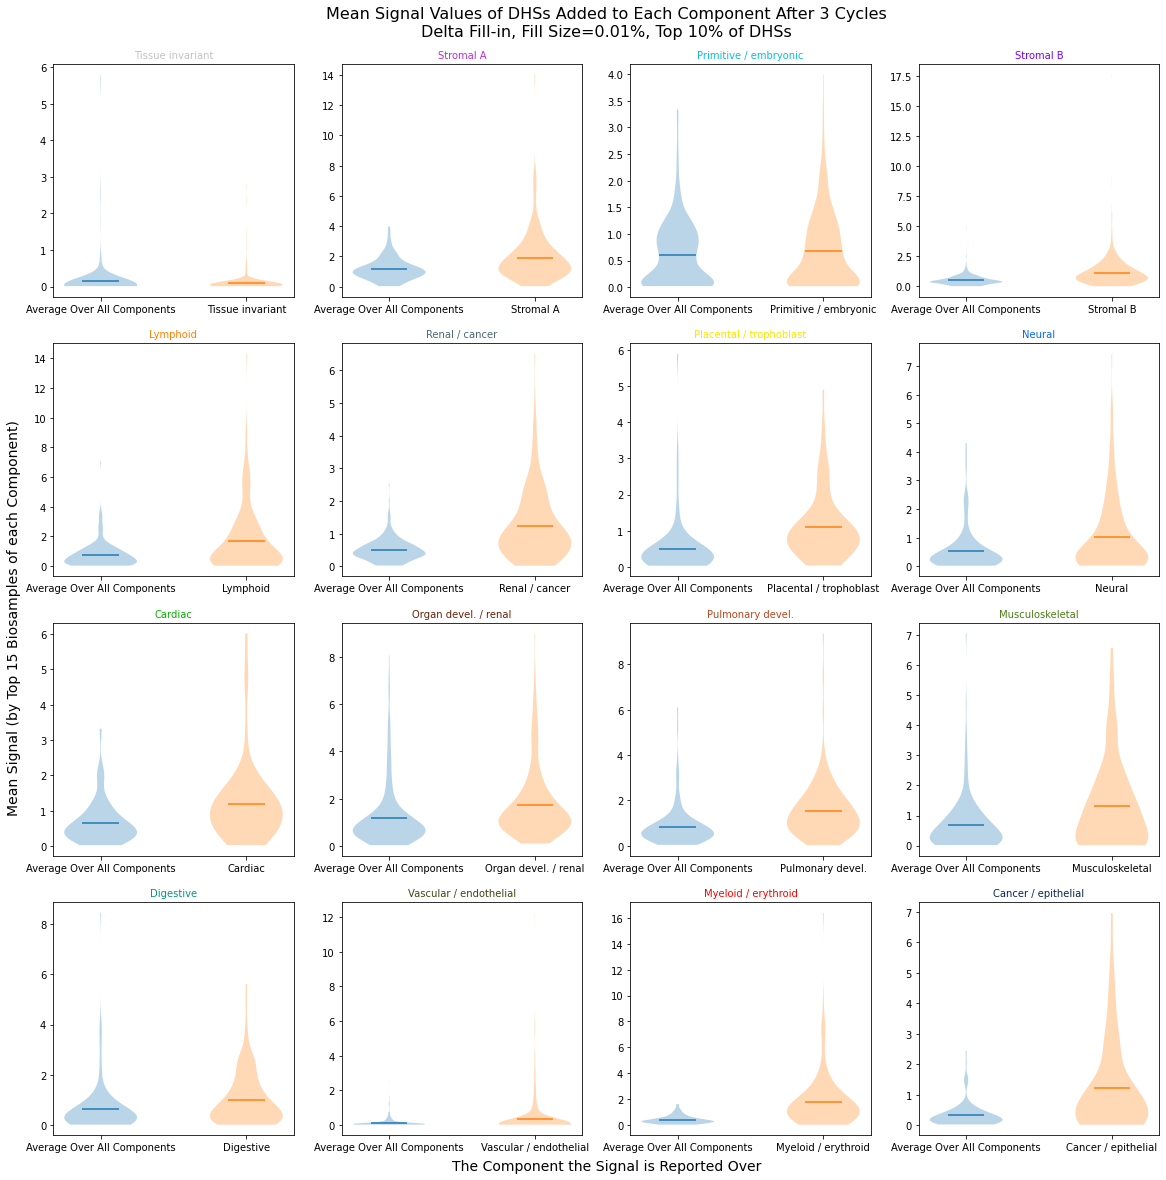

In [102]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(cycle_3_added_top_10_percent_dhss_average_over_all_comps[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(cycle_3_added_top_10_percent_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
#     ax.set_ylim([0, 10])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
#     ax.legend(handles, ['Average Over All Components', nmf_comps[ind]])
#     ax.legend(['All Components Averaged', 'All Components Mean', nmf_comps[ind], nmf_comps[ind]+' Mean'])
#     ax.set_xticks([])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Average Over All Components', nmf_comps[ind]])




fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of DHSs Added to Each Component After 3 Cycles\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [42]:
#for each reference component, finding the signal value for the DHSs that were dropped from that component 
#across all other components
    
all_reference_comps_mean_signal_dropped_only_1_cycle = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_dropped_cycle_1[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_dropped_only_1_cycle.append(reference_comp)
    
all_reference_comps_mean_signal_dropped_only_2_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_dropped_cycle_2[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_dropped_only_2_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_dropped_only_3_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_dropped_cycle_3[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_dropped_only_3_cycles.append(reference_comp)

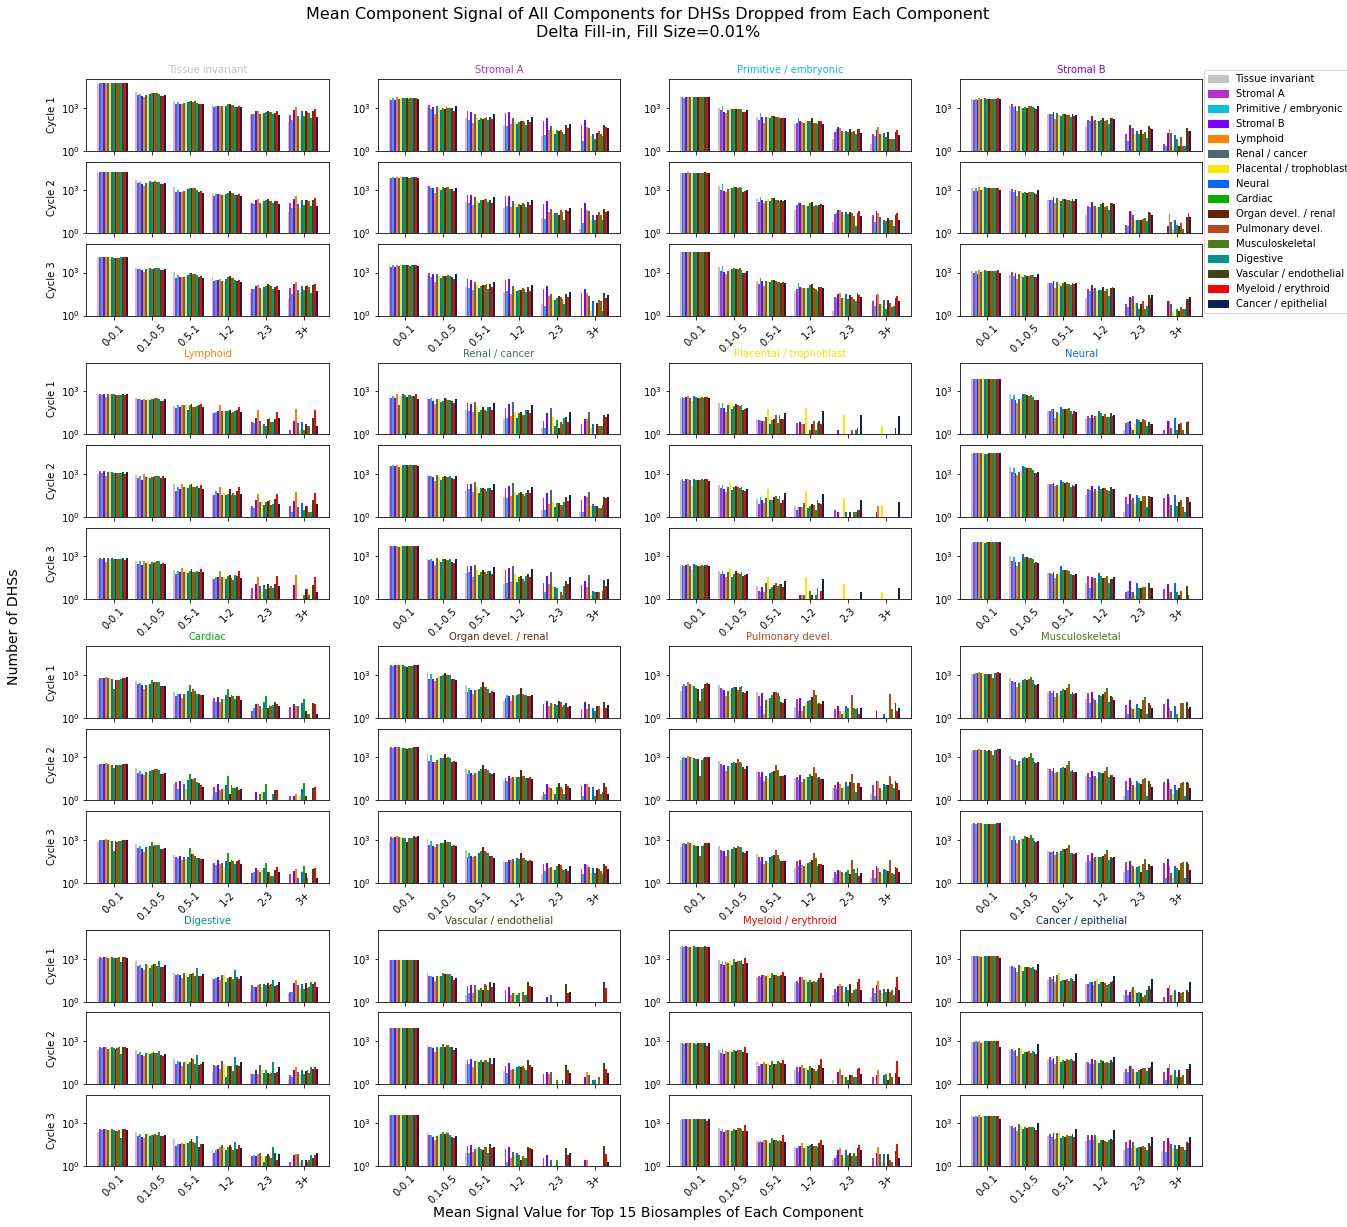

In [54]:
nrows = 4
ncols = 4
naxes = 3
bins = [0, 0.1, 0.5, 1, 2, 3, 1000.0]
fig = plt.figure(figsize=(20, 20))
fig.patch.set_facecolor('white')
for i in range(16):
    ax = axes_grid.Grid(fig, (nrows, ncols, i+1), (naxes, 1), axes_pad=0.15)
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_dropped_only_1_cycle[i][j], bins)
        ax[0].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[0].set_ylim([1, 100000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_dropped_only_2_cycles[i][j], bins)
        ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[1].set_ylim([1, 100000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_dropped_only_3_cycles[i][j], bins)
        ax[2].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[2].set_ylim([1, 100000])
        
    if i%4==0:
        ax[0].set_ylabel('Cycle 1')
        ax[1].set_ylabel('Cycle 2')
        ax[2].set_ylabel('Cycle 3')
    
#     if i//4==3:
#         ax[1].set_xlabel('3 Cycles')
    
    ax[2].set_xticks(list(np.arange(6)))
    ax[2].set_xticklabels(['0-0.1', '0.1-0.5', '0.5-1', '1-2', '2-3', '3+'], rotation=45)
    ax[0].set_title(nmf_comps[i], fontsize=10, color=color[i])

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.893, 0.745))
fig.text(0.515, 0.09, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of All Components for DHSs Dropped from Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.515, y=0.93)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

In [38]:
#for each reference component, finding the signal value for the DHSs that were added to that component 
#across all other components
    
all_reference_comps_mean_signal_added_only_1_cycle = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_added_cycle_1[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_added_only_1_cycle.append(reference_comp)
    
all_reference_comps_mean_signal_added_only_2_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_added_cycle_2[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_added_only_2_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_added_only_3_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_added_cycle_3[i]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_added_only_3_cycles.append(reference_comp)

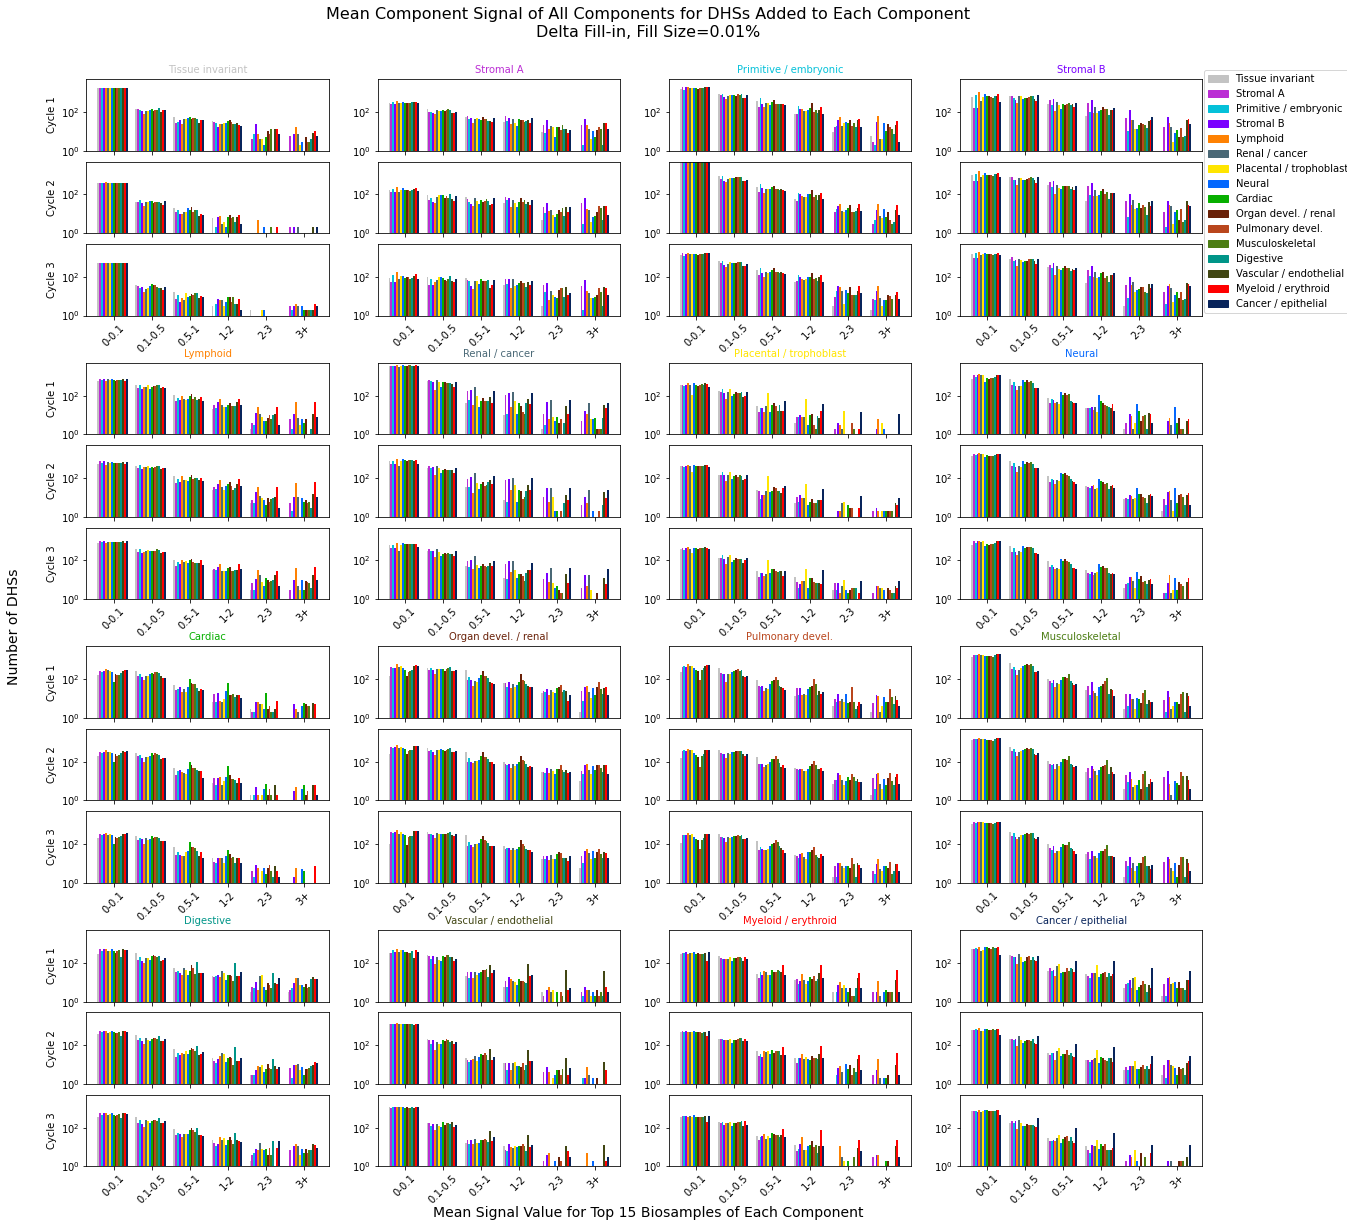

In [48]:
nrows = 4
ncols = 4
naxes = 3
bins = [0, 0.1, 0.5, 1, 2, 3, 1000.0]
fig = plt.figure(figsize=(20, 20))
fig.patch.set_facecolor('white')
for i in range(16):
    ax = axes_grid.Grid(fig, (nrows, ncols, i+1), (naxes, 1), axes_pad=0.15)
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_added_only_1_cycle[i][j], bins)
        ax[0].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[0].set_ylim([1, 5000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_added_only_2_cycles[i][j], bins)
        ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[1].set_ylim([1, 5000])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_added_only_3_cycles[i][j], bins)
        ax[2].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[2].set_ylim([1, 5000])
        
    if i%4==0:
        ax[0].set_ylabel('Cycle 1')
        ax[1].set_ylabel('Cycle 2')
        ax[2].set_ylabel('Cycle 3')
    
#     if i//4==3:
#         ax[1].set_xlabel('3 Cycles')
    
    ax[2].set_xticks(list(np.arange(6)))
    ax[2].set_xticklabels(['0-0.1', '0.1-0.5', '0.5-1', '1-2', '2-3', '3+'], rotation=45)
    ax[0].set_title(nmf_comps[i], fontsize=10, color=color[i])

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.893, 0.745))
fig.text(0.515, 0.09, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of All Components for DHSs Added to Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.515, y=0.93)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

In [10]:
#for each reference component, finding the signal value for these DHSs across other components
all_reference_comps_mean_signal_0_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_0_cycles[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_0_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_1_cycle = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_1_cycle[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_1_cycle.append(reference_comp)
    
all_reference_comps_mean_signal_2_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_2_cycles[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_2_cycles.append(reference_comp)
    
all_reference_comps_mean_signal_3_cycles = []
for i in range(16):
    reference_comp = []
    DHSs = DHS_metadata.loc[DHSs_for_each_comp_3_cycles[i][0]]['identifier'].astype(str)
    for j in range(16):
        reference_comp.append(list(all_comps_average_signal.loc[DHSs]['comp'+str(j)+' mean']))
    all_reference_comps_mean_signal_3_cycles.append(reference_comp)

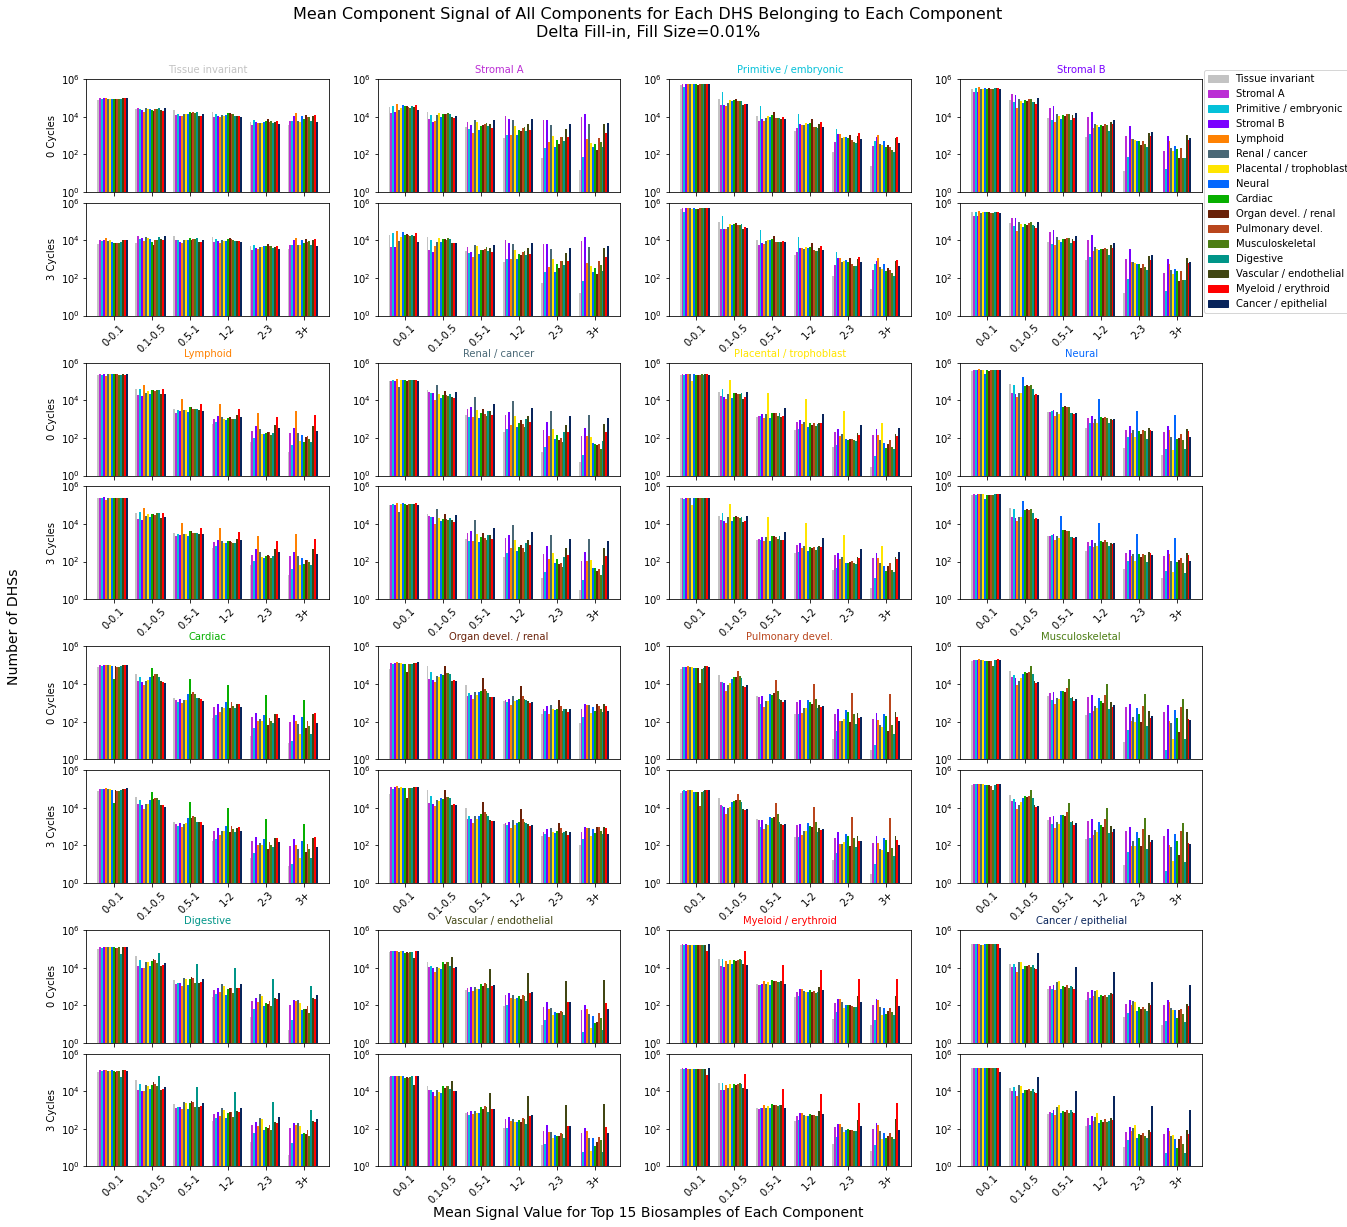

In [57]:
nrows = 4
ncols = 4
naxes = 2
bins = [0, 0.1, 0.5, 1, 2, 3, 1000.0]
fig = plt.figure(figsize=(20, 20))
fig.patch.set_facecolor('white')
for i in range(16):
    ax = axes_grid.Grid(fig, (nrows, ncols, i+1), (naxes, 1), axes_pad=0.15)
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_0_cycles[i][j], bins)

        ax[0].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[0].set_ylim([1, 1000000])
#     for j in range(16):
#         hist, b = np.histogram(all_reference_comps_mean_signal_1_cycle[i][j], bins)
#         ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
#     for j in range(16):
#         hist, b = np.histogram(all_reference_comps_mean_signal_2_cycles[i][j], bins)
#         ax[2].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
    for j in range(16):
        hist, b = np.histogram(all_reference_comps_mean_signal_3_cycles[i][j], bins)

        ax[1].bar(np.arange(6)-((8-j)*0.05), hist, width=0.05, log=True, color=color[j])
        ax[1].set_ylim([1, 1000000])
        
    if i%4==0:
        ax[0].set_ylabel('0 Cycles')
        ax[1].set_ylabel('3 Cycles')
    
#     if i//4==3:
#         ax[1].set_xlabel('3 Cycles')
    
    ax[1].set_xticks(list(np.arange(6)))
    ax[1].set_xticklabels(['0-0.1', '0.1-0.5', '0.5-1', '1-2', '2-3', '3+'], rotation=45)
    ax[0].set_title(nmf_comps[i], fontsize=10, color=color[i])

handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
fig.legend(handles, nmf_comps, loc = (0.893, 0.745))
fig.text(0.515, 0.09, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(0.07, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of All Components for Each DHS Belonging to Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.515, y=0.93)
plt.subplots_adjust(wspace=0.2, hspace=0.2)
plt.show()

In [13]:
#making ROIurls for the top dropped DHSs (best cases)
print('Dropped Cycle 1:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_1[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=True).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = original_decomp_Mixture_top_comps[dhs_ind]
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(1, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_best_cases', drop_info))
print()

print('Dropped Cycle 2:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_2[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=True).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(2, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_best_cases', drop_info))
print()

print('Dropped Cycle 3:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_3[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=True).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(3, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_best_cases', drop_info))

Dropped Cycle 1:
Tissue invariant
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Tissue_invariant_best_cases_CT20220113.bed
Stromal A
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_A_best_cases_CT20220113.bed
Primitive / embryonic
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Primitive_embryonic_best_cases_CT20220113.bed
Stromal B
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_B_best_cases_CT20220113.bed
Lymphoid
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_

Neural
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Neural_best_cases_CT20220113.bed
Cardiac
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Cardiac_best_cases_CT20220113.bed
Organ devel. / renal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Organ_devel._renal_best_cases_CT20220113.bed
Pulmonary devel.
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Pulmonary_devel._best_cases_CT20220113.bed
Musculoskeletal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_f

In [14]:
#making ROIurls for the top dropped DHSs (worst cases)
print('Dropped Cycle 1:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_1[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=False).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = original_decomp_Mixture_top_comps[dhs_ind]
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(1, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_worst_cases', drop_info))
print()

print('Dropped Cycle 2:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_2[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=False).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_1_cycle_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(2, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_worst_cases', drop_info))
print()

print('Dropped Cycle 3:')
for comp in range(16):
    top_100_identifiers = all_comps_average_signal.loc[DHS_metadata.loc[DHSs_dropped_cycle_3[comp]]['identifier']].sort_values(['comp'+str(comp)+' mean'], ascending=False).iloc[:100].index
    top_100_inds = DHS_metadata_identifier_based.loc[top_100_identifiers]['ind']
    top_100_new_comp_inds = new_decomp_Mixture_all_delta_0001_3_cycles_top_comps_filtered[top_100_inds]
    #finding the new comp for each dropped DHS
    change = []
    new_comps = []
    for new_comp_ind, identifier, dhs_ind in zip(top_100_new_comp_inds, top_100_identifiers, top_100_inds):
        #if the DHS is dropped
        if np.isnan(new_comp_ind):
            new_comps.append('Dropped')
            change.append('Dropped')
        else:
            #if the DHS is not dropped
            new_comp_ind = new_comp_ind.astype(int)
            top_dhs_comp_ind = int(all_comps_average_signal.loc[identifier]['max signal'].strip('comp').strip(' mean'))
            new_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(new_comp_ind)+' mean']
            old_comp_ind = new_decomp_Mixture_all_delta_0001_2_cycles_top_comps_filtered[dhs_ind].astype(int)
            old_comp_signal = all_comps_average_signal.loc[identifier]['comp'+str(old_comp_ind)+' mean']
            #if the new component has the largest mean signal for that DHS
            if top_dhs_comp_ind == new_comp_ind:
                change.append('Optimal')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' #')
            elif new_comp_signal > old_comp_signal:
                change.append('Agreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15] + ' +')
            else:
                change.append('Disagreeable')
                new_comps.append(nmf_comps[new_comp_ind].replace(' / ', '/')[:15])
    original_chr = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['seqname'])
    original_start = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['start'])
    original_end = list(DHS_metadata_identifier_based.loc[top_100_identifiers]['end'])
    drop_info = [new_comps, original_chr, original_start, original_end]
    print(nmf_comps[comp])
    print(make_roi_url_dropped_DHSs(3, nmf_comps[comp].replace(' ', '_').replace('_/', '')+'_worst_cases', drop_info))

Dropped Cycle 1:
Tissue invariant
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Tissue_invariant_worst_cases_CT20220113.bed
Stromal A
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_A_worst_cases_CT20220113.bed
Primitive / embryonic
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Primitive_embryonic_worst_cases_CT20220113.bed
Stromal B
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_1_from_Stromal_B_worst_cases_CT20220113.bed
Lymphoid
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F

Neural
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Neural_worst_cases_CT20220113.bed
Cardiac
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Cardiac_worst_cases_CT20220113.bed
Organ devel. / renal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Organ_devel._renal_worst_cases_CT20220113.bed
Pulmonary devel.
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle_3_from_Pulmonary_devel._worst_cases_CT20220113.bed
Musculoskeletal
https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2FNMF_dropped_DHSs_cycle

In [68]:
mask1 = DHS_metadata['start']==185149920
mask2 = DHS_metadata['end']==185150500
mask3 = DHS_metadata['seqname']=='chr3'

DHS_metadata[mask1 & mask2 & mask3]
#chr3:185149920-185150500

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component,ind
2300485,chr3,185149920,185150500,3.9403673,0.38103,4,185150180,185150000.0,185150286.0,Cardiac,2300485


In [69]:
print(nmf_comps[np.argmax(decomp_Mixture[:, 2300485])])
print(nmf_comps[np.argmax(new_decomp_Mixture_all_delta_0001_1_cycle[:, 2300485])])
print(nmf_comps[np.argmax(new_decomp_Mixture_all_delta_0001_2_cycles[:, 2300485])])
print(nmf_comps[np.argmax(new_decomp_Mixture_all_delta_0001_3_cycles[:, 2300485])])
# new_decomp_Mixture_all_delta_0001_3_cycles_sum[3185010]

Cardiac
Digestive
Cardiac
Cardiac


Text(0.5, 1.03, 'Number of Samples for DHSs of Each Component\nDelta Fill-in, Fill Size=0.01%')

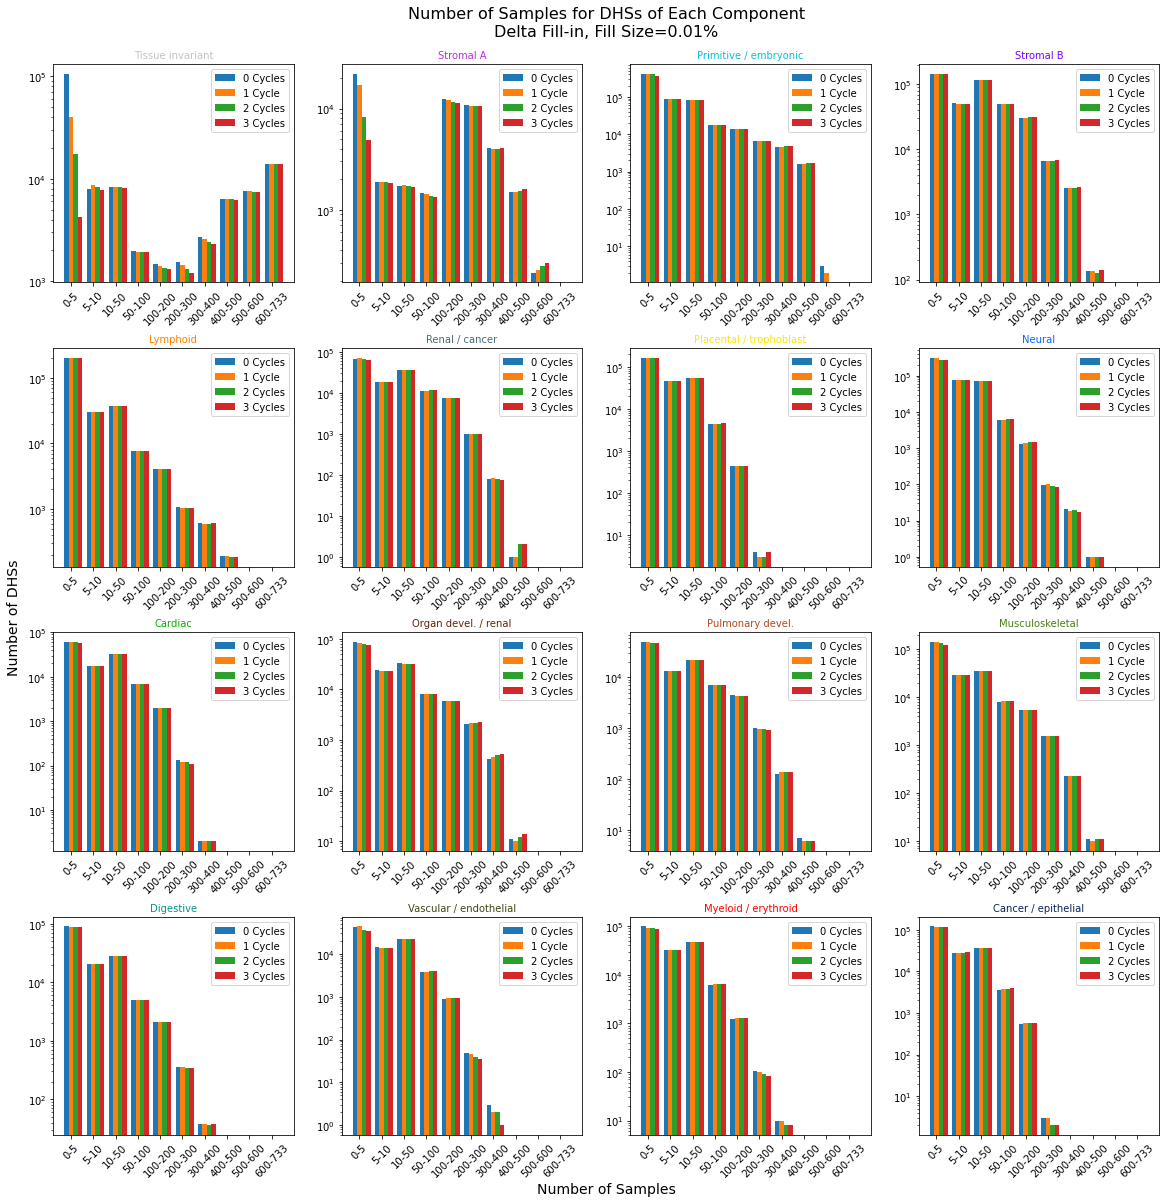

In [35]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

bins = [0, 5, 10, 50, 100, 200, 300, 400, 500, 600, 733]
axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    data = [DHSs_for_each_comp_numsamples_0_cycles[ind], DHSs_for_each_comp_numsamples_1_cycle[ind], DHSs_for_each_comp_numsamples_2_cycles[ind], DHSs_for_each_comp_numsamples_3_cycles[ind]]
    hist, b = np.histogram(data[0], bins)
    ax.bar(np.arange(10)-0.2, hist, width=0.2, log=True) 
    hist, b = np.histogram(data[1], bins)
    ax.bar(np.arange(10)-0.0, hist, width=0.2, log=True)
    hist, b = np.histogram(data[2], bins)
    ax.bar(np.arange(10)+0.2, hist, width=0.2, log=True)
    hist, b = np.histogram(data[3], bins)
    ax.bar(np.arange(10)+0.4, hist, width=0.2, log=True)
    
    ax.set_xticks(list(np.arange(10)))
    ax.set_xticklabels(['0-5', '5-10', '10-50', '50-100', '100-200', '200-300', '300-400', '400-500', '500-600', '600-733'], rotation=45)
    
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
    ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
    
fig.text(0.5, 0.0, 'Number of Samples', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Number of Samples for DHSs of Each Component\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.03)

Text(0.5, 1.03, 'Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%')

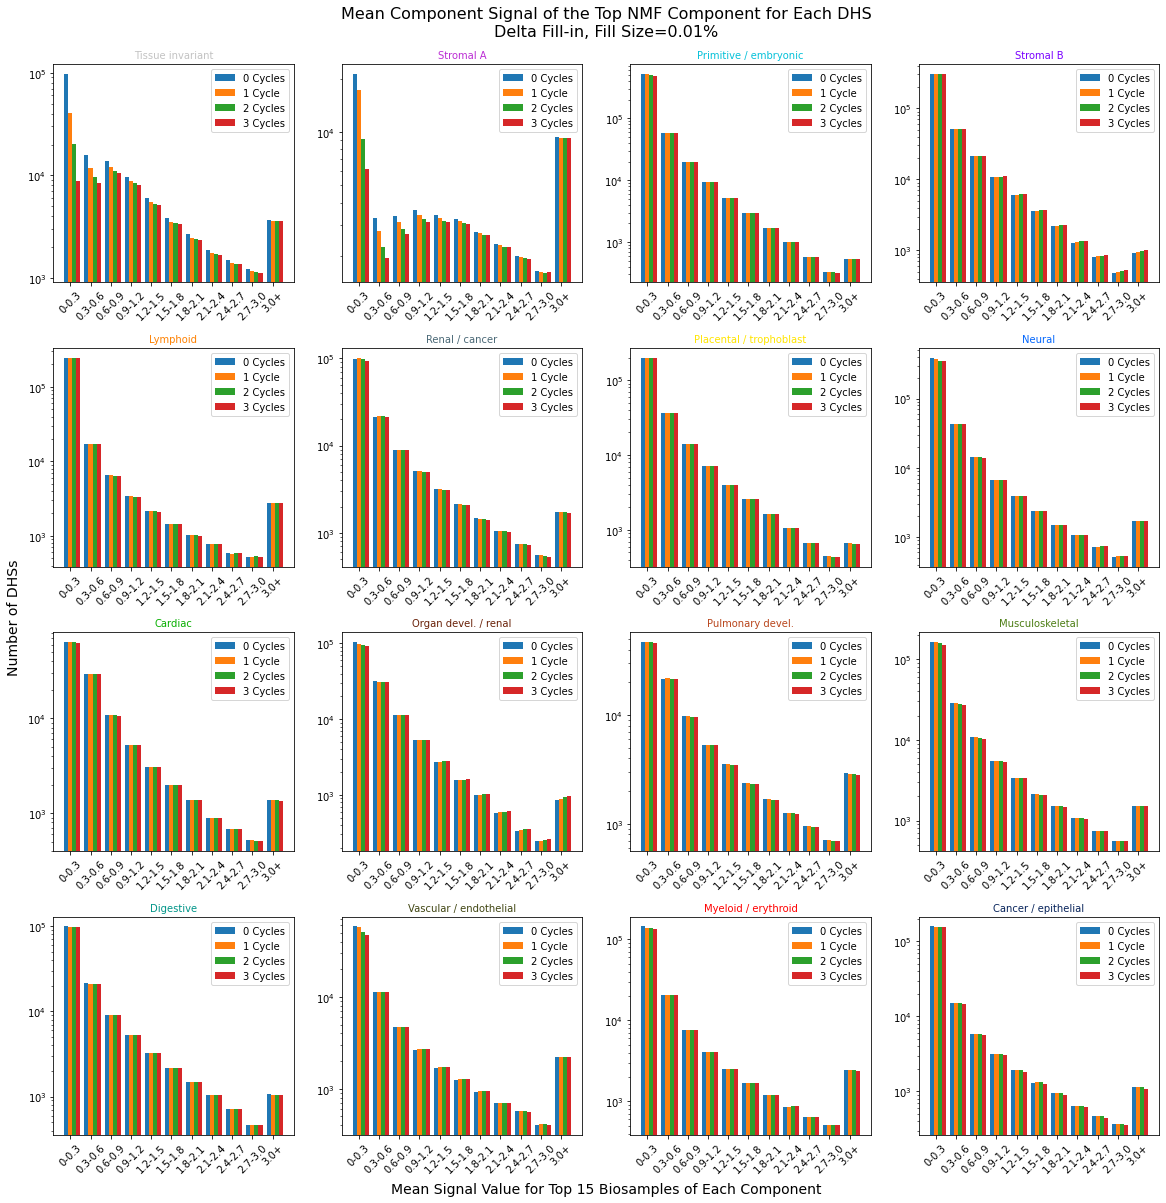

In [88]:
#with 3.0+ bin
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.3)
fig.patch.set_facecolor('white')

# bin_max = [3, 5, 2, 2.5, 1.5, 3, 2.5, 2, 3, 3, 4, 2, 3, 3, 3, 2]
bins = [0, 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3.0, 1000.0]
axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    data = [DHSs_for_each_comp_mean_comp_signal_0_cycles[ind], DHSs_for_each_comp_mean_comp_signal_1_cycle[ind], DHSs_for_each_comp_mean_comp_signal_2_cycles[ind], DHSs_for_each_comp_mean_comp_signal_3_cycles[ind]]
    hist, b = np.histogram(data[0], bins)
    ax.bar(np.arange(11)-0.2, hist, width=0.2, log=True) 
    hist, b = np.histogram(data[1], bins)
    ax.bar(np.arange(11)-0.0, hist, width=0.2, log=True)
    hist, b = np.histogram(data[2], bins)
    ax.bar(np.arange(11)+0.2, hist, width=0.2, log=True)
    hist, b = np.histogram(data[3], bins)
    ax.bar(np.arange(11)+0.4, hist, width=0.2, log=True)
    
    ax.set_xticks(list(np.arange(11)))
    ax.set_xticklabels(['0-0.3', '0.3-0.6', '0.6-0.9', '0.9-1.2', '1.2-1.5', '1.5-1.8', '1.8-2.1', '2.1-2.4', '2.4-2.7', '2.7-3.0', '3.0+'], rotation=45)
    
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
    ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
    
fig.text(0.5, 0.0, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.03)

In [84]:
#Without 3.0+ bin
# fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
# fig.patch.set_facecolor('white')

# # bin_max = [3, 5, 2, 2.5, 1.5, 3, 2.5, 2, 3, 3, 4, 2, 3, 3, 3, 2]
# bins_manual = [0, 0.3, 0.6, 0.9, 1.2, 1.5, 1.8, 2.1, 2.4, 2.7, 3.0]
# axes = axes.ravel()

# for ax, ind in zip(axes, range(16)):
# #     bins = range(0, int(np.ceil(max(all_comps_average_signal['comp' + str(ind) + ' mean']))), 10)
# #     bins = np.arange(0, 3, 0.3)
#     bins = bins_manual
#     data = [DHSs_for_each_comp_mean_comp_signal_0_cycles[ind], DHSs_for_each_comp_mean_comp_signal_1_cycle[ind], DHSs_for_each_comp_mean_comp_signal_2_cycles[ind], DHSs_for_each_comp_mean_comp_signal_3_cycles[ind]]
#     ax.hist(data, bins=bins, log=True)
    
#     ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])
#     ax.legend(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'])
# #     print('%s 0 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_0_cycles[ind])))
# #     print('%s 1 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_1_cycle[ind])))
# #     print('%s 2 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_2_cycles[ind])))
# #     print('%s 3 cycle mean signal average: %s' %(nmf_comps[ind], np.mean(DHSs_for_each_comp_mean_comp_signal_3_cycles[ind])))
# #     print()
    
# fig.text(0.465, 0, 'Mean Signal Value for Top 15 Biosamples of Each Component', ha='center', fontsize=14)
# fig.text(-0.02, 0.5, 'Number of DHSs', va='center', rotation='vertical', fontsize=14)
# plt.suptitle('Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.465, y=1.03)

Text(0.465, 1.03, 'Average Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%')

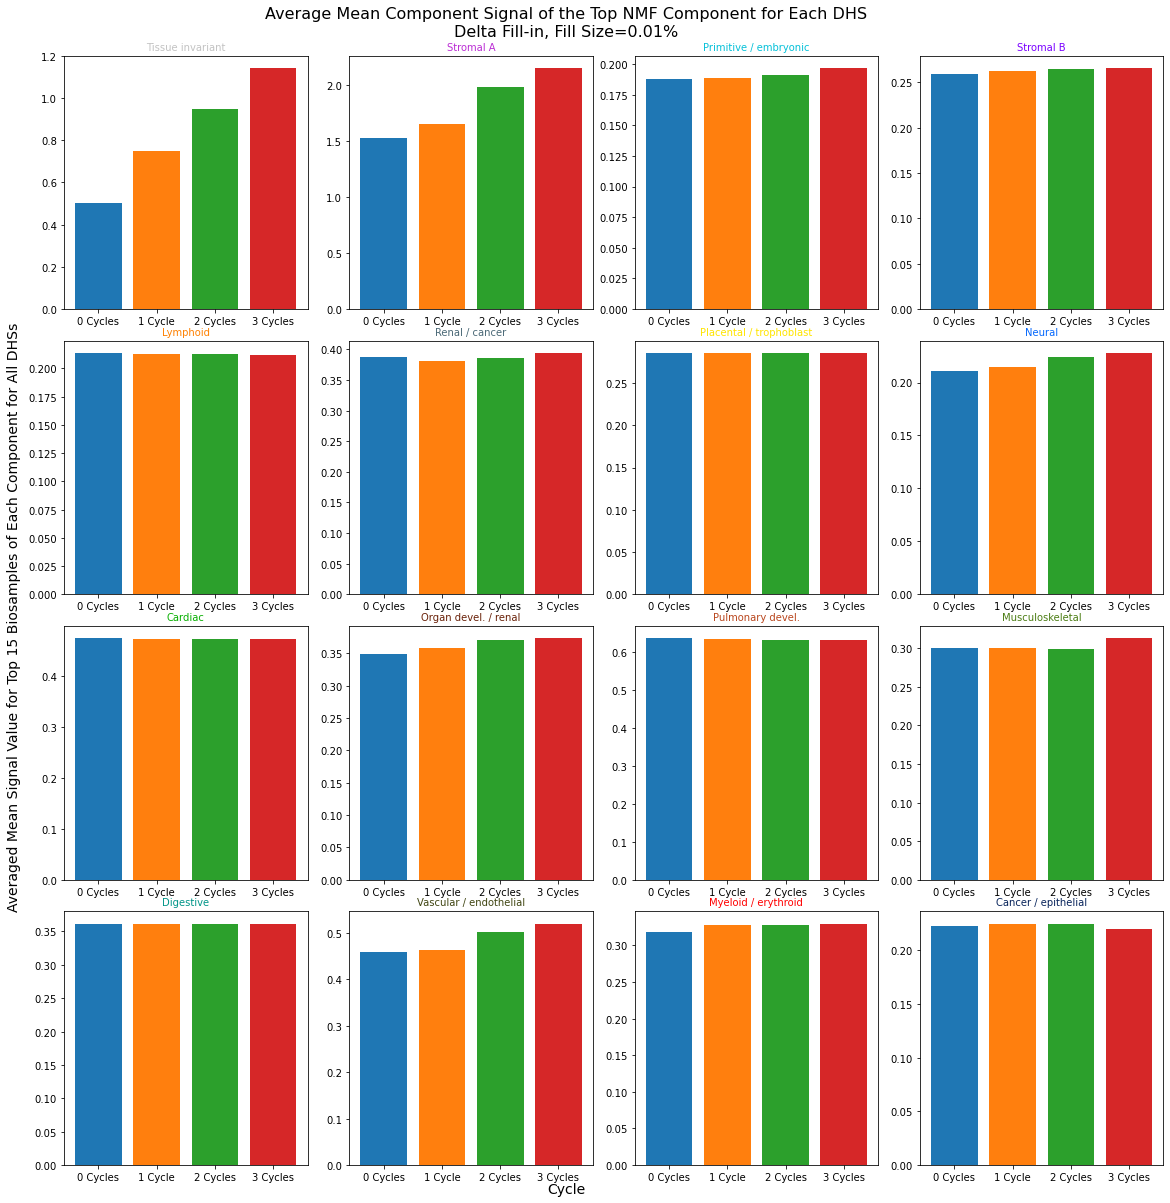

In [75]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
fig.tight_layout()
fig.patch.set_facecolor('white')

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
#     bins = range(0, int(np.ceil(max(all_comps_average_signal['comp' + str(ind) + ' mean']))), 10)
    bins = np.arange(0, 3, 0.3)
    data = [np.mean(DHSs_for_each_comp_mean_comp_signal_0_cycles[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_1_cycle[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_2_cycles[ind]), np.mean(DHSs_for_each_comp_mean_comp_signal_3_cycles[ind])]
    ax.bar(['0 Cycles', '1 Cycle', '2 Cycles', '3 Cycles'], data, color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'])
    ax.set_title(nmf_comps[ind], fontsize=10, color=color[ind])

fig.text(0.465, 0, 'Cycle', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Averaged Mean Signal Value for Top 15 Biosamples of Each Component for All DHSs', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Average Mean Component Signal of the Top NMF Component for Each DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.465, y=1.03)

In [10]:
#creates ROIurl links for recommended DHSs
def make_roi_url_dropped_DHSs(cycle_num, comp, drop_info):
    today = date.today()
    bed_path_name = os.path.join('/home/ctrader/public_html/', 'NMF_dropped_DHSs_cycle_' + str(cycle_num) + '_from_' + str(comp) + '_CT' + today.strftime("%Y%m%d") + '.bed')
    f= open(bed_path_name, 'w')
    for i in range(100):
        f.write(drop_info[1][i] + '\t' + str(drop_info[2][i]) + '\t' + str(drop_info[3][i]) + '\t' + drop_info[0][i] + '\n')
    f.close()
    link_path = 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + 'NMF_dropped_DHSs_cycle_' + str(cycle_num) + '_from_' + str(comp) + '_CT' + today.strftime("%Y%m%d") + '.bed'
    return link_path